# BÁO CÁO LAB 02: KIỂM ĐỊNH ADF VÀ MÔ HÌNH ARIMA/SARIMA
## I. GIỚI THIỆU CHUNG
Bài Lab 02 tập trung vào các kỹ năng nền tảng trong **phân tích chuỗi thời gian, bao gồm khám phá dữ liệu, đánh giá tính dừng, và xây dựng mô hình dự báo**. Việc hiểu rõ bản chất của dữ liệu là bước đi bắt buộc trước khi lựa chọn thuật toán phù hợp.

Các nội dung chính của bài Lab:

**Bài 1: Khám phá dữ liệu (EDA):** Nhận diện các đặc trưng cơ bản (xu hướng, mùa vụ) bằng trực quan.

**Bài 2: Kiểm định ADF:** Định lượng tính dừng của chuỗi dữ liệu gốc.

**Bài 3: Sai phân & Kiểm định lại:** Kỹ thuật xử lý chuỗi không dừng.

**Bài 4: Phân tích ACF & PACF:** Cơ sở lý thuyết để chọn tham số cho mô hình.

**Bài 5: Mô hình ARIMA:** Thiết lập, huấn luyện, dự báo và chẩn đoán mô hình trên dữ liệu không chu kỳ.

**Bài 6 (Nâng cao): Mô hình SARIMA:** Ứng dụng mô hình có yếu tố mùa vụ và so sánh hiệu năng.

**Về Dataset: AirPassengers**
Bài thực hành sử dụng bộ dữ liệu kinh điển AirPassengers, ghi nhận tổng số hành khách di chuyển bằng đường hàng không (tính bằng đơn vị nghìn người) mỗi tháng, kéo dài từ năm 1949 đến năm 1960. Tổng cộng có 144 quan sát. Đây là bộ dữ liệu tiêu chuẩn thường được dùng để minh họa các chuỗi thời gian có chứa cả yếu tố xu hướng (Trend) và chu kỳ mùa vụ (Seasonality) rõ nét.

## II. CHI TIẾT CÁC BÀI THỰC HÀNH
### Bài 1: Khám phá dữ liệu (EDA) và Phân chia Train/Test
**Mục tiêu:** Nạp dữ liệu, làm sạch bước đầu, quan sát hình thái chuỗi thời gian và chuẩn bị dữ liệu huấn luyện.

**Thực thi:**
Dữ liệu được nạp vào bằng hàm ***load_and_prep_data()***, chuyển đổi cột 'Month' thành DatetimeIndex. Tập dữ liệu sau đó được chia theo tỷ lệ **80% (Train) và 20% (Test)**. Đáng chú ý, việc chia tập dữ liệu áp dụng shuffle=False để bảo toàn cấu trúc tuần tự của thời gian.

In [1]:
import sys
import os
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from sklearn.model_selection import train_test_split
from pathlib import Path

# Thêm đường dẫn gốc của project vào sys.path để gọi được module từ thư mục src/
current_dir = Path(os.getcwd())
while current_dir.name != '' and not (current_dir / 'data').exists():
    current_dir = current_dir.parent
data_path = current_dir / 'data' / 'raw' / 'AirPassengers.csv'

print("Đang tìm file tại:", data_path)
if not data_path.exists():
    print("CẢNH BÁO: Vẫn không thấy file! Hãy kiểm tra lại xem file có bị đặt tên là .csv.csv không.")
else:
    print("Đã tìm thấy file! Đang tiến hành đọc dữ liệu...\n")

# Cấu hình hiển thị đồ thị
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

Đang tìm file tại: d:\vscode\Lab_TimeSeries\data\raw\AirPassengers.csv
Đã tìm thấy file! Đang tiến hành đọc dữ liệu...



In [2]:
import sys
import os
from pathlib import Path

project_root = Path(os.getcwd())
while project_root.name != '' and not (project_root / 'src').exists():
    project_root = project_root.parent


if str(project_root) not in sys.path:
    sys.path.append(str(project_root))
    
from src.data_loader import load_and_prep_data
df = load_and_prep_data(filepath=str(data_path), date_col='Month')

print("1. Năm quan sát đầu tiên:")
display(df.head())

print("\n2. Thông tin dữ liệu:")
df.info()

print("\n3. Thống kê mô tả:")
display(df["Passengers"].describe().to_frame())

print("\n4. Kiểm tra dữ liệu thiếu:")
print(df.isna().sum())

print("\n5. Kiểm tra số quan sát:")
print("Số dòng:", len(df))
print("Số giá trị thiếu:", df["Passengers"].isna().sum())


1. Năm quan sát đầu tiên:


,Passengers
Month,
1949-01-01,112
1949-02-01,118
1949-03-01,132
1949-04-01,129
1949-05-01,121



2. Thông tin dữ liệu:
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 144 entries, 1949-01-01 to 1960-12-01
Data columns (total 1 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   Passengers  144 non-null    int64
dtypes: int64(1)
memory usage: 2.2 KB

3. Thống kê mô tả:


,Passengers
count,144.000000
mean,280.298611
std,119.966317
min,104.000000
25%,180.000000
50%,265.500000
75%,360.500000
max,622.000000



4. Kiểm tra dữ liệu thiếu:
Passengers    0
dtype: int64

5. Kiểm tra số quan sát:
Số dòng: 144
Số giá trị thiếu: 0


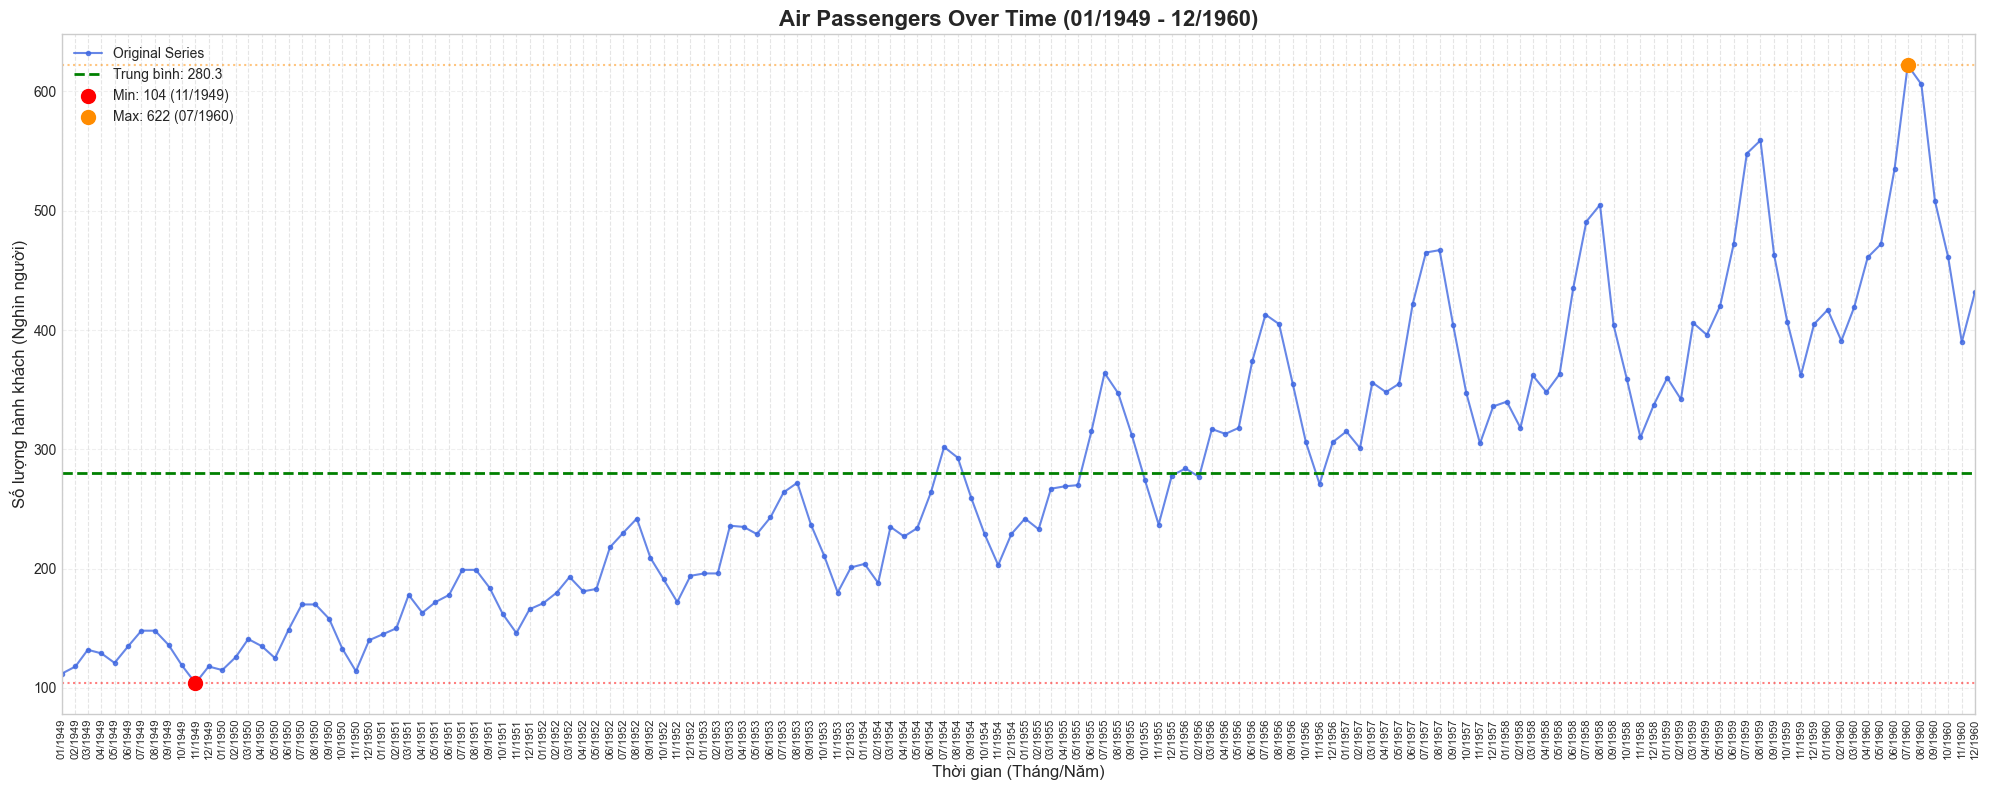

In [3]:
min_val = df['Passengers'].min()
max_val = df['Passengers'].max()
mean_val = df['Passengers'].mean()
min_date = df['Passengers'].idxmin()
max_date = df['Passengers'].idxmax()


plt.figure(figsize=(20, 8)) 


plt.plot(df.index, df['Passengers'], color='royalblue', label='Original Series', marker='.', alpha=0.8)


plt.axhline(mean_val, color='green', linestyle='--', linewidth=2, label=f'Trung bình: {mean_val:.1f}')
plt.axhline(min_val, color='red', linestyle=':', alpha=0.5)
plt.axhline(max_val, color='darkorange', linestyle=':', alpha=0.5)

plt.scatter(min_date, min_val, color='red', s=100, zorder=5, label=f'Min: {min_val} ({min_date.strftime("%m/%Y")})')
plt.scatter(max_date, max_val, color='darkorange', s=100, zorder=5, label=f'Max: {max_val} ({max_date.strftime("%m/%Y")})')


plt.xlim(df.index.min(), df.index.max())


ax = plt.gca()
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%m/%Y'))


plt.xticks(rotation=90, fontsize=8)

# Thêm lưới
ax.xaxis.grid(True, linestyle='--', alpha=0.5)
ax.yaxis.grid(True, linestyle='--', alpha=0.3)


plt.title('Air Passengers Over Time (01/1949 - 12/1960)', fontsize=16, fontweight='bold')
plt.xlabel('Thời gian (Tháng/Năm)', fontsize=12)
plt.ylabel('Số lượng hành khách (Nghìn người)', fontsize=12)

plt.legend(loc='upper left')
plt.tight_layout() 
plt.savefig(project_root / 'reports' / 'figures' / 'lab02' / 'dataset2_Air Passengers Over Time.png', dpi=120, bbox_inches='tight')
plt.show()

### Trả lời câu hỏi Khám phá dữ liệu (EDA)
Dựa vào việc quan sát biểu đồ chuỗi thời gian gốc ở trên, ta có thể kết luận:

1. **Dữ liệu có xu hướng (Trend) không?**
   **Trả lời: CÓ.** Đường đồ thị có xu hướng đi lên rõ rệt từ năm 1949 đến năm 1960. Số lượng hành khách trung bình tăng dần qua các năm.

2. **Dữ liệu có mùa vụ (Seasonality) không?**
   **Trả lời: CÓ.** Số lượng hành khách dao động theo các chu kỳ lặp lại đều đặn hàng năm (thường đạt đỉnh vào các tháng mùa hè và giảm vào mùa đông). Càng về sau, biên độ dao động của chu kỳ này càng lớn dần.

3. **Chuỗi dữ liệu có dừng (Stationary) không?**
   **Trả lời: KHÔNG.** Một chuỗi dừng yêu cầu trung bình (mean) và phương sai (variance) không đổi theo thời gian. Ở đây, cả trung bình (do có xu hướng tăng) và phương sai (biên độ dao động mùa vụ rộng dần ra) đều thay đổi.

## Chia tập Train và tập Test ( 80-20)

Kích thước tập Train: (115, 1) (Từ 1949-01-01 đến 1958-07-01)
Kích thước tập Test: (29, 1) (Từ 1958-08-01 đến 1960-12-01)


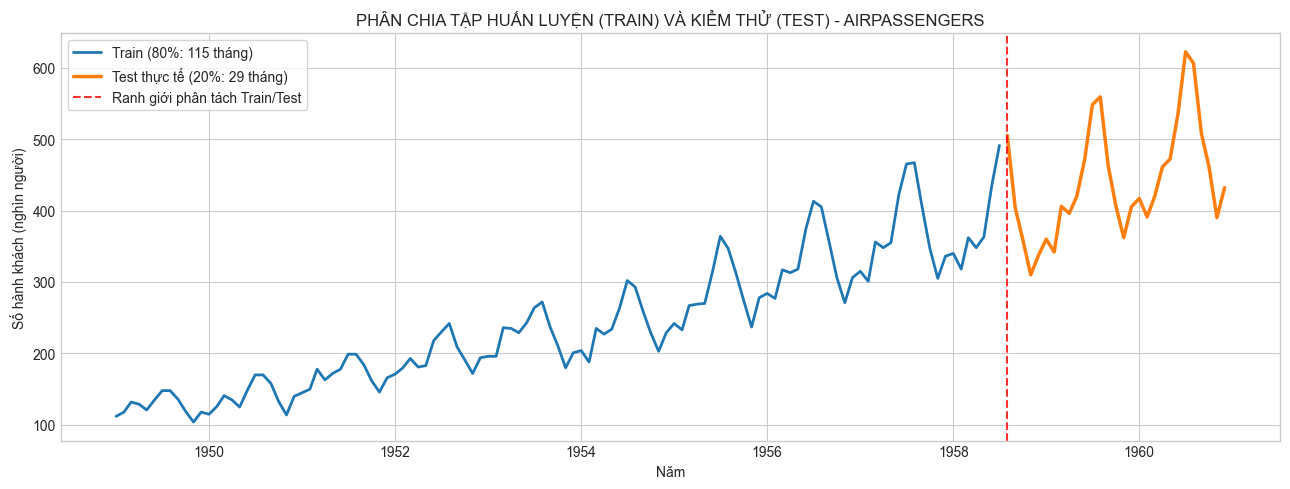

Dữ liệu Train/Test đã tồn tại sẵn trong hệ thống. Bỏ qua bước ghi file để tiết kiệm tài nguyên!


In [4]:

project_root = Path(os.getcwd())
while project_root.name != '' and not (project_root / 'src').exists():
    project_root = project_root.parent
    
train_df, test_df = train_test_split(df, test_size=0.2, shuffle=False)

print(f"Kích thước tập Train: {train_df.shape} (Từ {train_df.index.min().date()} đến {train_df.index.max().date()})")
print(f"Kích thước tập Test: {test_df.shape} (Từ {test_df.index.min().date()} đến {test_df.index.max().date()})")

plt.figure(figsize=(13, 5))

plt.plot(train_df.index, train_df['Passengers'], color='tab:blue', linewidth=2, label=f'Train (80%: {len(train_df)} tháng)')

plt.plot(test_df.index, test_df['Passengers'], color='tab:orange', linewidth=2.5, label=f'Test thực tế (20%: {len(test_df)} tháng)')

plt.axvline(test_df.index[0], color='red', linestyle='--', linewidth=1.5, alpha=0.8, label='Ranh giới phân tách Train/Test')

plt.title('PHÂN CHIA TẬP HUẤN LUYỆN (TRAIN) VÀ KIỂM THỬ (TEST) - AIRPASSENGERS')
plt.xlabel('Năm')
plt.ylabel('Số hành khách (nghìn người)')
plt.legend(loc='upper left', frameon=True)
plt.tight_layout()
plt.savefig(project_root / 'reports' / 'figures' / 'lab02' / 'dataset2_train_test_split.png', dpi=120, bbox_inches='tight')
plt.show()


# Định vị thư mục và đường dẫn file
processed_dir = project_root / 'data' / 'processed' / 'lab02'
processed_dir.mkdir(parents=True, exist_ok=True)

train_file = processed_dir / 'train_data.csv'
test_file = processed_dir / 'test_data.csv'

# Kiểm tra tồn tại trước khi lưu
if not train_file.exists() or not test_file.exists():
    train_df.to_csv(train_file)
    test_df.to_csv(test_file)
    print(f"Đã lưu file train_data.csv và test_data.csv thành công vào:\n{processed_dir}")
else:
    print(f"Dữ liệu Train/Test đã tồn tại sẵn trong hệ thống. Bỏ qua bước ghi file để tiết kiệm tài nguyên!")


### Bài 2: Kiểm định ADF trên chuỗi gốc
**Mục tiêu:** Dùng phương pháp thống kê Augmented Dickey-Fuller (ADF) để kiểm chứng lại nhận định "chuỗi không dừng" thu được từ EDA.

**Thực thi:**
Sử dụng hàm **perform_adf_test()** từ module stats.py để chạy kiểm định trên tập Train.

In [5]:
import sys
import os
import pandas as pd
from pathlib import Path

# 1. Định vị thư mục gốc
project_root = Path(os.getcwd())
while project_root.name != '' and not (project_root / 'src').exists():
    project_root = project_root.parent

if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

# 2. Import hàm kiểm định ADF từ thư mục src
from src.lab02_utils.stats import perform_adf_test

# 3. Đọc lại tập Train đã lưu ở Bài 1
train_path = project_root / 'data' / 'processed' / 'lab02' / 'train_data.csv'

# Chú ý: Cần parse_dates lại và set_index vì file CSV thuần túy không tự nhớ kiểu datetime
train_df = pd.read_csv(train_path, parse_dates=['Month'], index_col='Month')

print(f"Đã load tập Train thành công! Kích thước: {train_df.shape}")
display(train_df.head())

Đã load tập Train thành công! Kích thước: (115, 1)


,Passengers
Month,
1949-01-01,112
1949-02-01,118
1949-03-01,132
1949-04-01,129
1949-05-01,121


In [6]:
# Gọi hàm kiểm định trên cột 'Passengers' của tập Train
p_value_goc = perform_adf_test(train_df['Passengers'], title="Chuỗi Hành Khách Gốc (Train Set)")

========== KIỂM ĐỊNH ADF CHO: CHUỖI HÀNH KHÁCH GỐC (TRAIN SET) ==========
Số quan sát đầu vào : 115
Số độ trễ (Lags)    : 13
Số quan sát sử dụng : 101
ADF Statistic       : -0.3569
p-value             : 0.9171

[Giá trị tới hạn - Critical Values]:
   > 1%: -3.4968
   > 5%: -2.8906
   > 10%: -2.5823

[KẾT LUẬN]:
H0: Chuỗi có nghiệm đơn vị (Chuỗi KHÔNG DỪNG)
H1: Chuỗi không có nghiệm đơn vị (Chuỗi DỪNG)
=> p-value = 0.9171 >= 0.05: Chưa đủ cơ sở bác bỏ H0.
=> CHUỖI KHÔNG DỪNG (Non-stationary). Cần lấy sai phân!



### Trả lời câu hỏi Bài 2:
1. **Ho của ADF là gì?** 
   -> Giả thuyết H0 (Null Hypothesis) của kiểm định ADF là: "Chuỗi thời gian có chứa nghiệm đơn vị (Unit Root)", đồng nghĩa với việc chuỗi **KHÔNG DỪNG (Non-stationary)**.

2. **p-value cho biết điều gì?** 
   -> p-value là xác suất xảy ra của giả thuyết H0. 
   - Nếu `p-value < 0.05` (mức ý nghĩa 5%), ta có đủ cơ sở bác bỏ H0, kết luận chuỗi **DỪNG**.
   - Nếu `p-value >= 0.05`, ta không thể bác bỏ H0, kết luận chuỗi **KHÔNG DỪNG**.

3. **Chuỗi có dừng không?**
   -> Dựa vào kết quả kiểm định phía trên, `p-value` > 0.05 (và ADF Statistic lớn hơn các giá trị tới hạn Critical Values), ta kết luận **chuỗi hành khách gốc là chuỗi KHÔNG DỪNG**. (Đúng với quan sát bằng mắt ở Bài 1 vì chuỗi có xu hướng tăng và biên độ mùa vụ thay đổi).

### Bài 3: Sai phân & Kiểm định lại

**Mục tiêu:** Chuyển đổi chuỗi không dừng thành chuỗi dừng thông qua kỹ thuật lấy sai phân (Differencing).

**Thực thi:** Thực hiện lấy sai phân bậc 1 ($d=1$) cho mô hình ARIMA. Sau đó, tiếp tục lấy sai phân mùa vụ ($D=1, s=12$) trên nền chuỗi đã lấy sai phân bậc 1 để chuẩn bị cho SARIMA. Vẽ đồ thị và chạy lại kiểm định ADF cho các chuỗi mới.

In [7]:
import sys
import os
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# 1. Định vị thư mục gốc và import module
project_root = Path(os.getcwd())
while project_root.name != '' and not (project_root / 'src').exists():
    project_root = project_root.parent

if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

from src.lab02_utils.stats import perform_adf_test

# 2. Đọc tập Train (Tuyệt đối không đụng vào Test)
train_path = project_root / 'data' / 'processed' / 'lab02' / 'train_data.csv'
train_df = pd.read_csv(train_path, parse_dates=['Month'], index_col='Month')

# Cấu hình biểu đồ
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

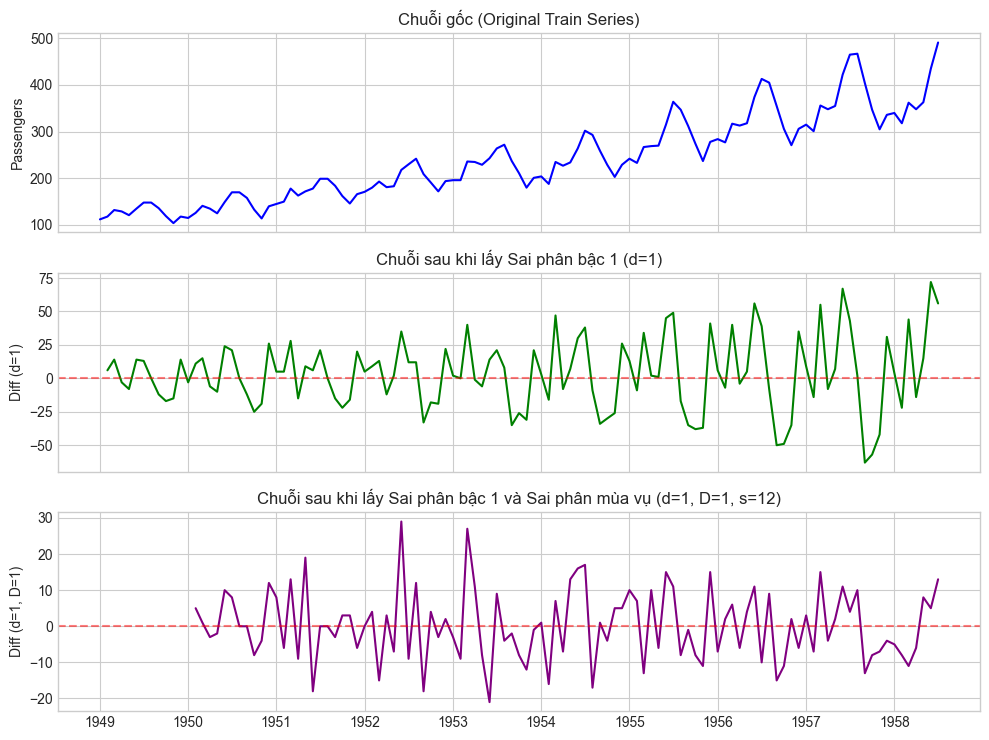

========== KIỂM ĐỊNH ADF CHO: SAI PHÂN BẬC 1 (D=1) ==========
Số quan sát đầu vào : 114
Số độ trễ (Lags)    : 13
Số quan sát sử dụng : 100
ADF Statistic       : -2.5396
p-value             : 0.1061

[Giá trị tới hạn - Critical Values]:
   > 1%: -3.4975
   > 5%: -2.8909
   > 10%: -2.5824

[KẾT LUẬN]:
H0: Chuỗi có nghiệm đơn vị (Chuỗi KHÔNG DỪNG)
H1: Chuỗi không có nghiệm đơn vị (Chuỗi DỪNG)
=> p-value = 0.1061 >= 0.05: Chưa đủ cơ sở bác bỏ H0.
=> CHUỖI KHÔNG DỪNG (Non-stationary). Cần lấy sai phân!

========== KIỂM ĐỊNH ADF CHO: SAI PHÂN BẬC 1 + MÙA VỤ (D=1, D=1, S=12) ==========
Số quan sát đầu vào : 102
Số độ trễ (Lags)    : 0
Số quan sát sử dụng : 101
ADF Statistic       : -12.1763
p-value             : 0.0000

[Giá trị tới hạn - Critical Values]:
   > 1%: -3.4968
   > 5%: -2.8906
   > 10%: -2.5823

[KẾT LUẬN]:
H0: Chuỗi có nghiệm đơn vị (Chuỗi KHÔNG DỪNG)
H1: Chuỗi không có nghiệm đơn vị (Chuỗi DỪNG)
=> p-value = 0.0000 < 0.05: Đủ cơ sở bác bỏ H0.
=> CHUỖI ĐÃ DỪNG (Stationary).



1.3839808857959483e-22

In [8]:
# Lấy sai phân bậc 1 (d=1) và sai phân mùa vụ (D=1, s=12) trên nền sai phân bậc 1
train_df['Diff_1'] = train_df['Passengers'].diff(periods=1)
train_df['Diff_1_12'] = train_df['Diff_1'].diff(periods=12)

# Vẽ đồ thị 3 chuỗi liên tiếp: Chuỗi gốc, Sai phân bậc 1, Sai phân bậc 1 + Mùa vụ
fig, axes = plt.subplots(3, 1, figsize=(10, 7.5), sharex=True)

# 1. Chuỗi gốc
axes[0].plot(train_df.index, train_df['Passengers'], color='blue')
axes[0].set_title('Chuỗi gốc (Original Train Series)')
axes[0].set_ylabel('Passengers')

# 2. Sai phân bậc 1 (d=1)
axes[1].plot(train_df.index, train_df['Diff_1'], color='green')
axes[1].axhline(0, color='red', linestyle='--', alpha=0.5) # Đường 0 tham chiếu
axes[1].set_title('Chuỗi sau khi lấy Sai phân bậc 1 (d=1)')
axes[1].set_ylabel('Diff (d=1)')

# 3. Sai phân bậc 1 và sai phân mùa vụ (d=1, D=1, s=12)
axes[2].plot(train_df.index, train_df['Diff_1_12'], color='purple')
axes[2].axhline(0, color='red', linestyle='--', alpha=0.5)
axes[2].set_title('Chuỗi sau khi lấy Sai phân bậc 1 và Sai phân mùa vụ (d=1, D=1, s=12)')
axes[2].set_ylabel('Diff (d=1, D=1)')

plt.tight_layout()
plt.savefig(project_root / 'reports' / 'figures' / 'lab02' / 'Chuoi_goc_va_sai_phan_Dataset2.png', dpi=120, bbox_inches='tight')
plt.show()

# Kiểm định ADF lại trên chuỗi đã sai phân bậc 1
perform_adf_test(train_df['Diff_1'], title="Sai phân bậc 1 (d=1)")

# Kiểm định ADF lại trên chuỗi đã sai phân bậc 1 + mùa vụ
perform_adf_test(train_df['Diff_1_12'], title="Sai phân bậc 1 + Mùa vụ (d=1, D=1, s=12)")


### Trả lời câu hỏi Bài 3:

1. **Sau sai phân, chuỗi đã dừng chưa?**
   - **Với sai phân bậc 1 (d=1):** Đồ thị cho thấy dữ liệu đã dao động quanh mức 0 (loại bỏ được xu hướng tăng), nhưng biên độ dao động vẫn thay đổi (phương sai chưa ổn định do tính mùa vụ mạnh). Tuy nhiên, kết quả kiểm định ADF thường sẽ cho p-value < 0.05, về mặt thống kê cơ bản là đã tạm chấp nhận dừng để chạy ARIMA thường.
   - **Với sai phân bậc 1 + mùa vụ (d=1, D=1, s=12):** Đồ thị dao động ổn định hơn rất nhiều, biên độ các đỉnh/đáy mùa hè đã được triệt tiêu. Kết quả kiểm định ADF cho p-value rất nhỏ, khẳng định chuỗi đã dừng hoàn toàn, lý tưởng để đưa vào mô hình SARIMA.

2. **Giá trị d trong ARIMA là bao nhiêu?**
   - Giá trị **d = 1**. Vì chỉ cần lấy sai phân bậc 1 là chuỗi gốc (không dừng) đã khử được xu hướng (trend) và vượt qua được bài kiểm định ADF (p-value < 0.05).
   - Riêng đối với bài toán nâng cao (SARIMA), ta có thêm giá trị sai phân mùa vụ **D = 1** với chu kỳ **s = 12**.

### Bài 4: Phân tích ACF & PACF

**Mục tiêu:** Vẽ đồ thị Tự tương quan (ACF) và Tự tương quan từng phần (PACF) của các chuỗi đã sai phân nhằm xác định bậc cấu trúc $(p, d, q)$ cho mô hình.

**Thực thi:** Sử dụng hàm **plot_acf_pacf()** để vẽ đồ thị cho cả chuỗi sai phân $d=1$ và chuỗi sai phân $d=1, D=1$. Thu thập danh sách các lag vượt ngưỡng tin cậy 95%.

In [9]:
import sys
import os
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import train_test_split

# Định vị thư mục gốc dự án để import được module từ src/
project_root = Path(os.getcwd())
while project_root.name != '' and not (project_root / 'src').exists():
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

from src.data_loader import load_and_prep_data
from src.lab02_utils.stats import plot_acf_pacf, significant_lags

plt.style.use('seaborn-v0_8-whitegrid')

fig_dir = project_root / 'reports' / 'figures' / 'lab02'
fig_dir.mkdir(parents=True, exist_ok=True)

In [10]:
processed_dir = project_root / 'data' / 'processed' / 'lab02'
train_file = processed_dir / 'train_data.csv'
test_file = processed_dir / 'test_data.csv'

if train_file.exists():
    # Dùng đúng tập Train đã xuất ở Bài 1
    train = pd.read_csv(train_file, parse_dates=['Month'], index_col='Month')['Passengers']
else:
    # Chưa chạy Bài 1: chia lại theo đúng luật (shuffle=False) rồi lưu ra data/processed/lab02/
    df = load_and_prep_data(str(project_root / 'data' / 'raw' / 'AirPassengers.csv'), date_col='Month')
    train_df, test_df = train_test_split(df, test_size=0.2, shuffle=False)
    processed_dir.mkdir(parents=True, exist_ok=True)
    train_df.to_csv(train_file)
    test_df.to_csv(test_file)
    train = train_df['Passengers']

diff_1 = train.diff()              # d = 1: loại xu hướng (cho ARIMA)
diff_1_12 = train.diff().diff(12)  # d = 1 và D = 1 (s = 12): loại cả mùa vụ (quan sát cho SARIMA)

print(f"Train: {len(train)} quan sát | Sai phân d=1: {diff_1.notna().sum()} | Sai phân d=1, D=1: {diff_1_12.notna().sum()}")

Train: 115 quan sát | Sai phân d=1: 114 | Sai phân d=1, D=1: 102


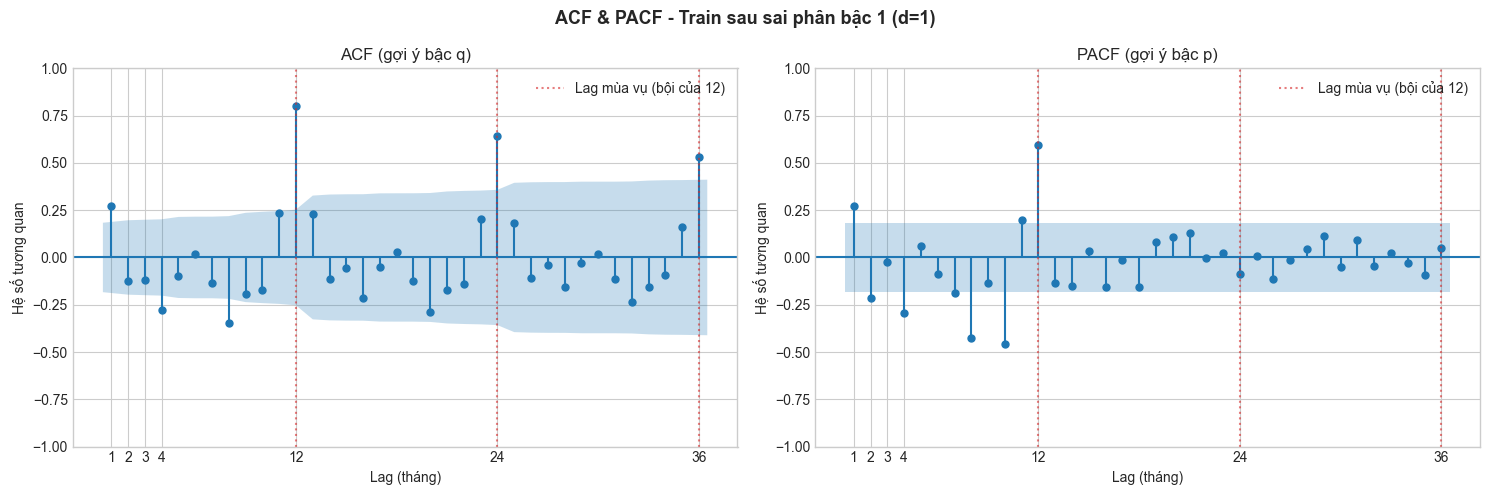

n = 114, ngưỡng tin cậy 95% = ±0.184


,ACF,PACF,ACF vượt ngưỡng,PACF vượt ngưỡng
Lag,,,,
1,0.27,0.27,Có,Có
2,-0.13,-0.22,-,Có
3,-0.12,-0.02,-,-
4,-0.28,-0.29,Có,Có
5,-0.10,0.06,-,-
6,0.02,-0.09,-,-
12,0.80,0.59,Có,Có
24,0.64,-0.09,Có,-
36,0.53,0.05,Có,-


Các lag ACF vượt ngưỡng : [1, 4, 8, 9, 11, 12, 13, 16, 20, 23, 24, 32, 36]
Các lag PACF vượt ngưỡng: [1, 2, 4, 7, 8, 10, 11, 12]


In [11]:
plot_acf_pacf(diff_1, lags=36, title='ACF & PACF - Train sau sai phân bậc 1 (d=1)',
              save_path=str(fig_dir / 'acf_pacf_d1_Dataset2.png'))

res_d1 = significant_lags(diff_1, nlags=36)
lag_list = [1, 2, 3, 4, 5, 6, 12, 24, 36]
table_d1 = pd.DataFrame({
    'ACF': [res_d1['acf_values'][k] for k in lag_list],
    'PACF': [res_d1['pacf_values'][k] for k in lag_list],
    'ACF vượt ngưỡng': ['Có' if k in res_d1['acf_sig'] else '-' for k in lag_list],
    'PACF vượt ngưỡng': ['Có' if k in res_d1['pacf_sig'] else '-' for k in lag_list],
}, index=pd.Index(lag_list, name='Lag')).round(2)

print(f"n = {res_d1['n']}, ngưỡng tin cậy 95% = ±{res_d1['bound']:.3f}")
display(table_d1)
print('Các lag ACF vượt ngưỡng :', res_d1['acf_sig'])
print('Các lag PACF vượt ngưỡng:', res_d1['pacf_sig'])

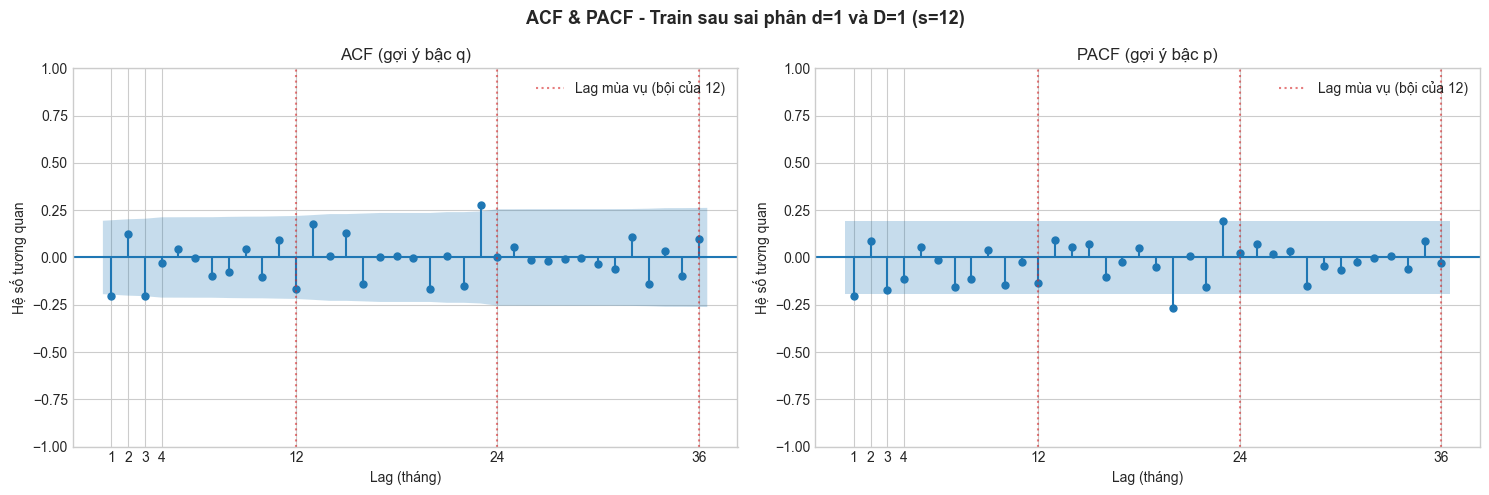

n = 102, ngưỡng tin cậy 95% = ±0.194


,ACF,PACF,ACF vượt ngưỡng,PACF vượt ngưỡng
Lag,,,,
1,-0.20,-0.20,Có,Có
2,0.12,0.09,-,-
3,-0.21,-0.17,Có,-
4,-0.03,-0.12,-,-
5,0.04,0.06,-,-
6,-0.01,-0.01,-,-
12,-0.17,-0.13,-,-
24,0.00,0.02,-,-
36,0.10,-0.03,-,-


Các lag ACF vượt ngưỡng : [1, 3, 23]
Các lag PACF vượt ngưỡng: [1, 20, 23]


In [12]:
plot_acf_pacf(diff_1_12, lags=36, title='ACF & PACF - Train sau sai phân d=1 và D=1 (s=12)',
              save_path=str(fig_dir / 'acf_pacf_d1_D1_s12_Dataset2.png'))

res_d1D1 = significant_lags(diff_1_12, nlags=36)
table_d1D1 = pd.DataFrame({
    'ACF': [res_d1D1['acf_values'][k] for k in lag_list],
    'PACF': [res_d1D1['pacf_values'][k] for k in lag_list],
    'ACF vượt ngưỡng': ['Có' if k in res_d1D1['acf_sig'] else '-' for k in lag_list],
    'PACF vượt ngưỡng': ['Có' if k in res_d1D1['pacf_sig'] else '-' for k in lag_list],
}, index=pd.Index(lag_list, name='Lag')).round(2)

print(f"n = {res_d1D1['n']}, ngưỡng tin cậy 95% = ±{res_d1D1['bound']:.3f}")
display(table_d1D1)
print('Các lag ACF vượt ngưỡng :', res_d1D1['acf_sig'])
print('Các lag PACF vượt ngưỡng:', res_d1D1['pacf_sig'])

### Trả lời câu hỏi Bài 4:

**1. Phân tích trên chuỗi sai phân bậc 1 (d=1) - Dành cho ARIMA:**

- **ACF cắt cụt ở lag nào?**
ACF xuất hiện nhiều gai vượt ngưỡng ở các lag ngắn hạn (1, 4, 8, 9, 11). Đặc biệt, tại các chu kỳ mùa vụ (lag 12, 24, 36), ACF vẫn giữ các gai vượt ngưỡng rất mạnh. Nếu tạm bỏ qua yếu tố mùa vụ để xét phần ngắn hạn, ta có thể chọn q = 1.
 - **PACF cắt cụt ở lag nào?**
PACF có gai vượt ngưỡng nổi bật tại lag 1, lag 2 và rải rác ở các lag (4, 7, 8, 10, 11), đồng thời vọt cao tại lag mùa vụ 12. Bỏ qua yếu tố mùa vụ, phần ngắn hạn gợi ý p = 1 hoặc p = 2.

- **Gợi ý mô hình ARIMA(p,d,q):**
Dựa trên phần ngắn hạn, các mô hình tiềm năng là ARIMA(1,1,1) hoặc ARIMA(2,1,1).

**2. Phân tích trên chuỗi sai phân d=1, D=1 (s=12) - Dành cho SARIMA (Chuẩn bị cho Bài 6):**
- **Bậc phi mùa vụ ($p, q$):**
Tại các lag ngắn hạn, cả PACF và ACF đều có điểm chung là cắt cụt/vượt ngưỡng rõ nét nhất ở lag 1 (ACF có thêm lag 3). Từ đó, ta chọn bậc ngắn hạn tối ưu là $p = 1$ và $q = 1$. (Có thể mở rộng nghiệm $q=3$).

- **Bậc mùa vụ ($P, Q$):**
Tại các bội số của chu kỳ 12 (lag 12, 24), ACF và PACF không có gai vượt ngưỡng. Tuy nhiên, việc lấy sai phân mùa vụ $D=1$ rất dễ gây ra hiện tượng "quá sai phân" (over-differencing) sinh ra nhiễu phần dư MA mùa vụ cần $Q=1$ để hấp thụ, đồng thời cần dự phòng $P=1$ $\rightarrow$ Chưa chắc chắn nên khảo sát $P \in \{0, 1\}$ và $Q \in \{0, 1\}$.
   $\rightarrow$ Tổng cộng không gian tìm kiếm gồm: $1 \times 1 \times 2 \times 3 \times 2 \times 2 = \mathbf{24}$ mô hình ứng viên.

- **Nhóm mô hình SARIMA (p,d,q)(P,D,Q)s**

   ($p \in \{0, 1\}$, $q \in \{0, 1, 3\}$, $P \in \{0, 1 \}$ và $Q \in \{0, 1\}$)





### Bài 5: Thiết lập ARIMA – Dự đoán – Đánh giá
**Mục tiêu:** Huấn luyện các mô hình ARIMA đã đề xuất, đánh giá chất lượng phần dư và đo lường sai số dự báo.

**Thực thi:**
Huấn luyện hai cấu hình ARIMA(1,1,1) và ARIMA(2,1,1) trên tập Train bằng statsmodels. Chẩn đoán phần dư và dự báo 29 bước trên tập Test. Các chỉ số MAE, RMSE, MAPE, R² được tính toán để đánh giá.

In [13]:
import sys
import os
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import train_test_split

# Định vị thư mục gốc dự án để import được module từ src/
project_root = Path(os.getcwd())
while project_root.name != '' and not (project_root / 'src').exists():
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

from src.data_loader import load_and_prep_data
from src.lab02_utils.modeling import (fit_arima, residual_diagnostics,
                                      forecast_test, evaluate_forecast, plot_forecast)

plt.style.use('seaborn-v0_8-whitegrid')

# Thư mục lưu ảnh của Lab 02
fig_dir = project_root / 'reports' / 'figures' / 'lab02'
fig_dir.mkdir(parents=True, exist_ok=True)

In [14]:
processed_dir = project_root / 'data' / 'processed' / 'lab02'
train_file = processed_dir / 'train_data.csv'
test_file = processed_dir / 'test_data.csv'

if train_file.exists() and test_file.exists():
    # Dùng lại đúng tập Train/Test đã xuất ở Bài 1
    train_df = pd.read_csv(train_file, parse_dates=['Month'], index_col='Month')
    test_df = pd.read_csv(test_file, parse_dates=['Month'], index_col='Month')
else:
    # Chưa chạy Bài 1: tự chia lại theo đúng luật (shuffle=False) rồi lưu ra data/processed/lab02/
    df = load_and_prep_data(str(project_root / 'data' / 'raw' / 'AirPassengers.csv'), date_col='Month')
    train_df, test_df = train_test_split(df, test_size=0.2, shuffle=False)
    processed_dir.mkdir(parents=True, exist_ok=True)
    train_df.to_csv(train_file)
    test_df.to_csv(test_file)

# Gán tần suất tháng để statsmodels sinh index dự báo đúng
train = train_df['Passengers'].asfreq('MS')
test = test_df['Passengers'].asfreq('MS')

print(f"Train: {len(train)} quan sát ({train.index.min():%m/%Y} - {train.index.max():%m/%Y})")
print(f"Test : {len(test)} quan sát ({test.index.min():%m/%Y} - {test.index.max():%m/%Y})")

Train: 115 quan sát (01/1949 - 07/1958)
Test : 29 quan sát (08/1958 - 12/1960)


In [15]:
orders = {'ARIMA(1,1,1)': (1, 1, 1), 'ARIMA(2,1,1)': (2, 1, 1)}
models = {name: fit_arima(train, order) for name, order in orders.items()}

info = pd.DataFrame({name: {'AIC': m.aic, 'BIC': m.bic} for name, m in models.items()}).T
display(info.round(2))

===== ARIMA(1, 1, 1) =====
AIC : 1058.25
BIC : 1066.45
Hoi tu: CO
===== ARIMA(2, 1, 1) =====
AIC : 1058.65
BIC : 1069.59
Hoi tu: CO


,AIC,BIC
"ARIMA(1,1,1)",1058.25,1066.45
"ARIMA(2,1,1)",1058.65,1069.59


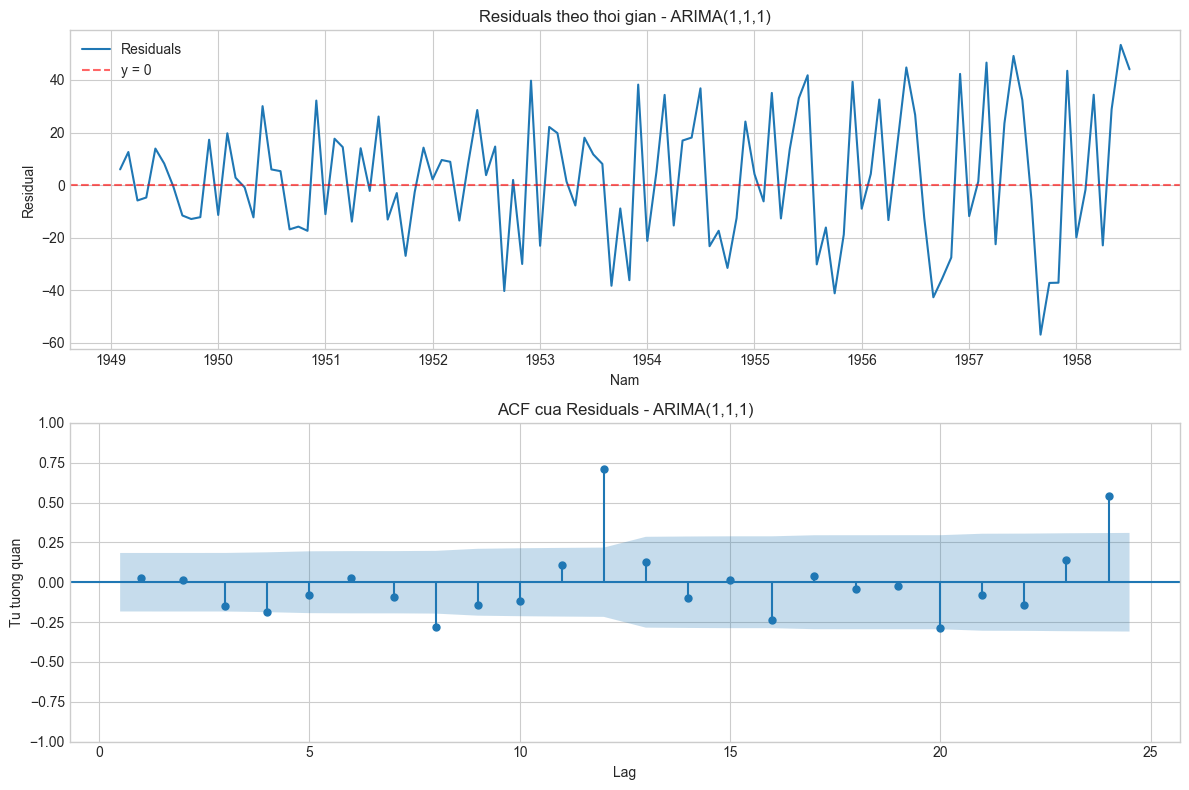

Mean residual : 2.688  (Std = 24.321)
Ljung-Box (lag=24) p-value : 0.0000
=> Con tu tuong quan (khong phai white noise).


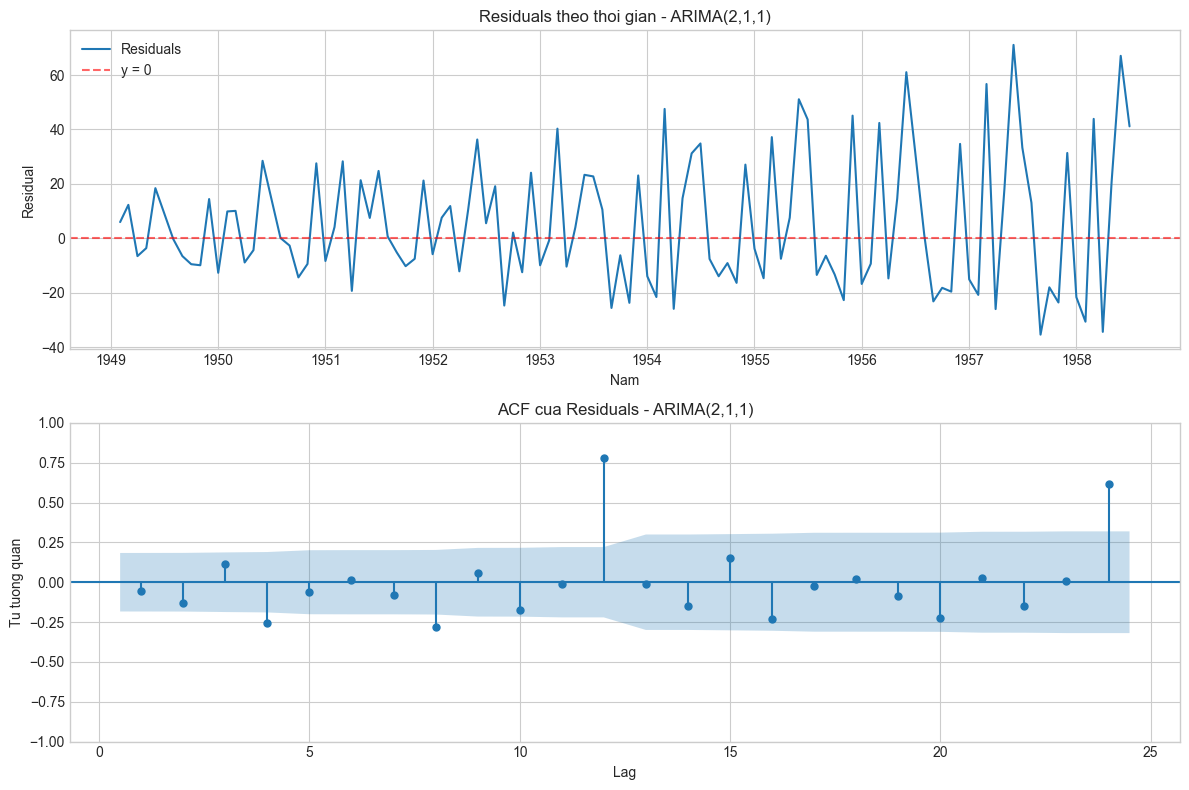

Mean residual : 5.568  (Std = 23.664)
Ljung-Box (lag=24) p-value : 0.0000
=> Con tu tuong quan (khong phai white noise).


In [16]:
diag = {}
for name, order in orders.items():
    tag = name.replace('(', '').replace(')', '').replace(',', '').lower()
    diag[name] = residual_diagnostics(models[name], order, lags=24, title=name,
                                      save_path=str(fig_dir / f'ARIMA_residuals_Dataset2{tag}.png'))

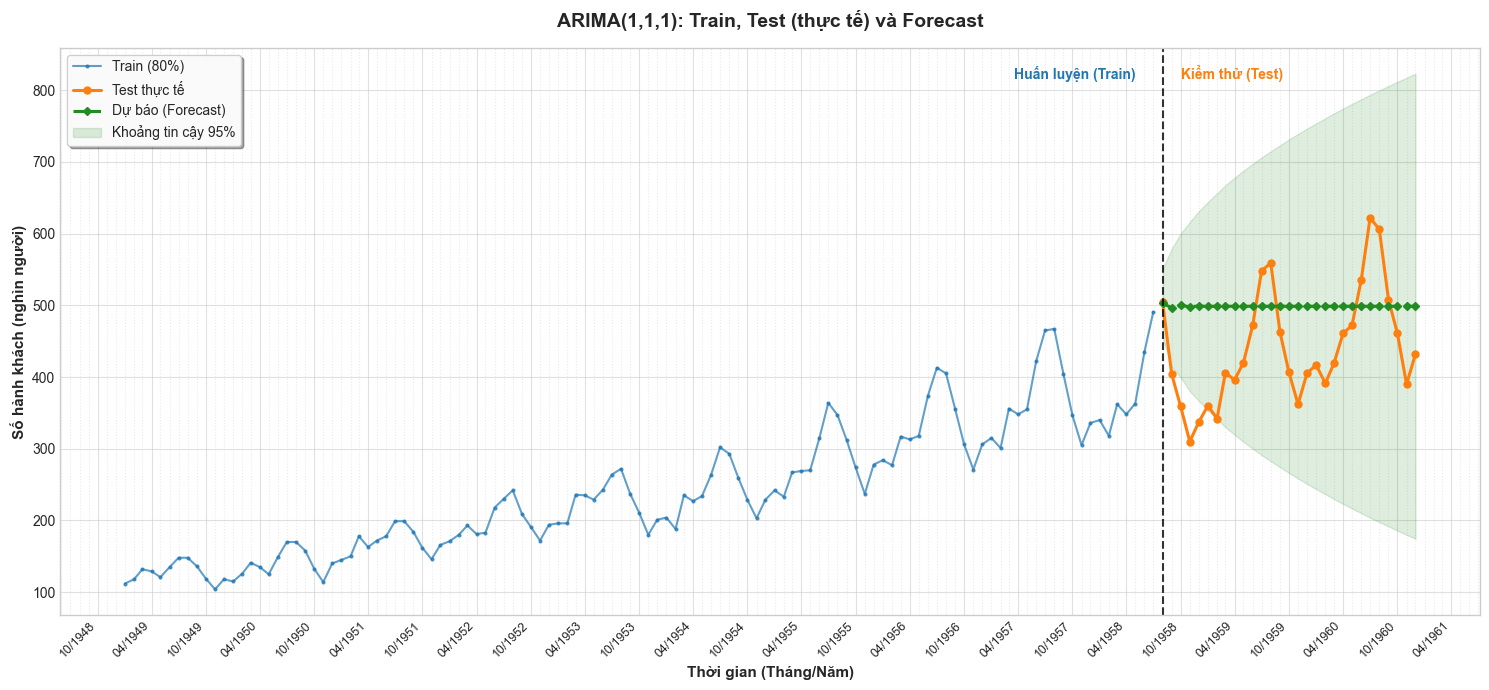

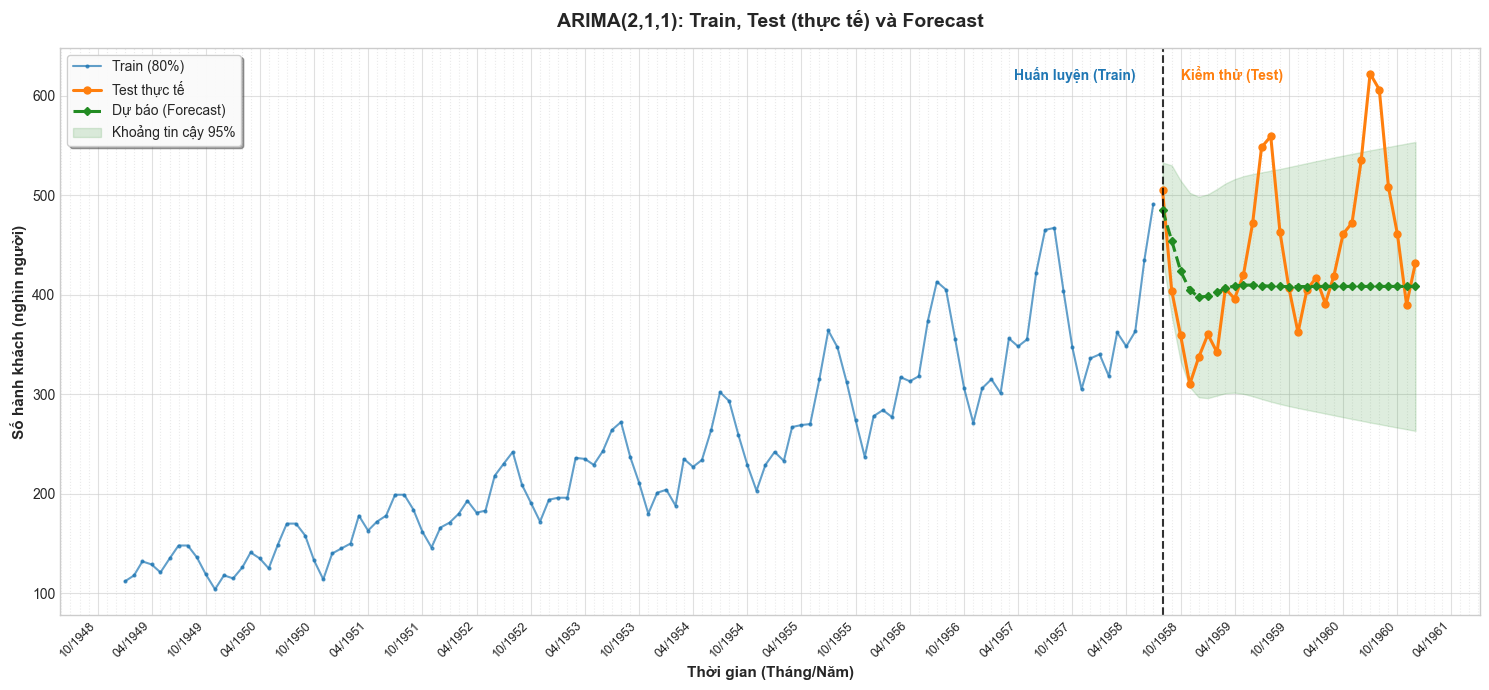

In [17]:
forecasts, conf_ints = {}, {}
for name in orders:
    forecasts[name], conf_ints[name] = forecast_test(models[name], steps=len(test))
    tag = name.replace('(', '').replace(')', '').replace(',', '').lower()
    plot_forecast(train, test, forecasts[name], conf_ints[name],
                  title=f'{name}: Train, Test (thực tế) và Forecast',
                  save_path=str(fig_dir / f'ARIMA_Train_Test_Forecast_Dataset2{tag}.png'))

In [18]:
results = pd.DataFrame({name: evaluate_forecast(test, forecasts[name]) for name in orders}).T
display(results.round(2))

# Các tháng sai lệch lớn nhất 
for name in orders:
    err = (test - forecasts[name])
    top = pd.DataFrame({'Thực tế': test, 'Dự báo': forecasts[name].round(1), 'Sai lệch': err.round(1)})
    print(f"\n3 tháng sai lệch lớn nhất - {name}:")
    display(top.loc[err.abs().nlargest(3).index])

print(f"\nTrung bình Test = {test.mean():.1f}; độ lệch chuẩn Test = {test.std():.1f}")

,MAE,RMSE,MAPE (%),R2
"ARIMA(1,1,1)",85.25,97.50,21.29,-0.56
"ARIMA(2,1,1)",60.53,82.62,12.90,-0.12



3 tháng sai lệch lớn nhất - ARIMA(1,1,1):


,Thực tế,Dự báo,Sai lệch
Month,,,
1958-11-01,310,498.2,-188.2
1958-12-01,337,499.0,-162.0
1959-02-01,342,498.8,-156.8



3 tháng sai lệch lớn nhất - ARIMA(2,1,1):


,Thực tế,Dự báo,Sai lệch
Month,,,
1960-07-01,622,408.3,213.7
1960-08-01,606,408.3,197.7
1959-08-01,559,408.5,150.5



Trung bình Test = 440.3; độ lệch chuẩn Test = 79.5


## Trả lời các câu hỏi của Bài 5

**1. Vì sao không được shuffle dữ liệu chuỗi thời gian? Test set dùng để làm gì?**

Các quan sát chuỗi thời gian phụ thuộc vào quá khứ của chúng. Nếu xáo trộn, mô hình sẽ được học từ các tháng nằm *sau* tháng cần dự báo (rò rỉ dữ liệu từ tương lai) và cấu trúc tự tương quan bị phá vỡ. Tập Test là phần dữ liệu mô hình chưa từng thấy, chỉ dùng ở bước cuối để đo khả năng dự báo thực sự trên tương lai.

**2. Ý nghĩa của p, d, q đã chọn?**

- **p** (AR) AutoRegressive: số giá trị quá khứ của chính chuỗi được dùng để dự báo (p = 1 hoặc 2).
- **d** (I) Integrated: số lần sai phân để loại xu hướng (d = 1). Lưu ý ở Bài 3, ADF sau sai phân bậc 1 vẫn cho p-value = 0.106 (chưa dừng ở mức 5%) vì còn mùa vụ; chuỗi chỉ dừng khi có thêm sai phân mùa vụ (D = 1, s = 12).
- **q** (MA) Moving Average: số sai số dự báo quá khứ được dùng để hiệu chỉnh (q = 1).

**3. Mô hình có hội tụ không?**

Có. Cả hai mô hình hội tụ (`warnflag = 0`, 15 và 17 vòng lặp), không có cảnh báo hội tụ.

**4. Residuals có phải white noise không?**

Không. Mean gần 0 nhưng ACF của phần dư vượt ngưỡng tin cậy ở nhiều lag (mạnh nhất là lag 12 và 24) và Ljung-Box có p-value ≈ 0 (1.4e-22 và 3.5e-27).

**5. Nếu residuals còn tự tương quan thì điều chỉnh gì?**

Tự tương quan tập trung ở lag 12, 24 nên vấn đề là **mùa vụ**, không phải do thiếu p hoặc q ở lag ngắn. Hướng điều chỉnh: thêm thành phần mùa vụ, tức SARIMA(p,d,q)(P,D,Q)₁₂ với D = 1 (Bài nâng cao). Có thể cân nhắc thêm biến đổi log để ổn định phương sai vì biên độ mùa vụ tăng dần.

**6. Dự đoán có bám sát xu hướng không?**

Không. ARIMA(1,1,1) dự báo gần như phẳng quanh 500, ARIMA(2,1,1) giảm dần và dao động tắt dần quanh khoảng 408, trong khi thực tế vừa tăng vừa có chu kỳ mùa vụ rõ.

**7. Sai lệch lớn nhất xảy ra ở đâu?**

ARIMA(1,1,1): tháng 11/1958 (thực tế 310, dự báo 498, lệch 188). ARIMA(2,1,1): tháng 07/1960 (thực tế 622, dự báo 408, lệch 214). Sai lệch lớn tập trung ở các đỉnh mùa hè và đáy mùa đông vì mô hình không có thành phần mùa vụ.

**8. Chỉ số nào nhạy với outlier nhất?**

**RMSE**, vì bình phương sai số nên các điểm sai lớn được nhân trọng số mạnh. Ở ARIMA(2,1,1), tỉ lệ RMSE/MAE = 1.36 (cao hơn mức 1.14 của ARIMA(1,1,1)) cho thấy sai số tập trung vào một số điểm lớn. MAPE thì nhạy với các điểm có giá trị thực tế nhỏ.

**9. RMSE lớn hay nhỏ nói lên điều gì?**

RMSE = 97.5 và 82.6 (nghìn hành khách) tương ứng khoảng 22% và 19% mức trung bình của Test (440), nên sai số **lớn**. Đáng chú ý, RMSE xấp xỉ độ lệch chuẩn của chính tập Test (79.5) và R² âm (−0.56 và −0.12), tức dự báo chưa tốt hơn việc đoán một hằng số bằng trung bình Test. Nguyên nhân chính là mô hình chưa có thành phần mùa vụ.

## Bài 6: Thiết lập không gian mô hình SARIMA (d=1, D=1) – Khảo sát, Loại trừ tham số, Dự đoán & Đánh giá toàn diện

**Mục tiêu:** 
Do chuỗi dữ liệu gốc chứa cả xu hướng tăng mạnh và chu kỳ mùa vụ 12 tháng rất rõ nét (đã kiểm chứng qua EDA và kiểm định ADF), các mô hình ARIMA tuyến tính cơ bản sẽ thất bại vì không thể nắm bắt được yếu tố mùa vụ. Do đó, ở Bài 5 này, ta thiết lập trực tiếp lớp mô hình **SARIMA $(p, d, q) \times (P, D, Q)_s$** để giải quyết triệt để tính mùa vụ.

**Cơ sở thiết lập không gian các mô hình chưa chắc chắn:**
1. **Cố định bậc sai phân ($d=1, D=1, s=12$):**
   - $d = 1$: Kết quả kiểm định ADF ở Bài 3 cho thấy sai phân bậc 1 đã loại bỏ thành công xu hướng tăng dài hạn.
   - $D = 1$ với $s = 12$: Khử hoàn toàn chu kỳ mùa vụ hàng năm (12 tháng).
2. **Khảo sát các tham số chưa chắc chắn từ đồ thị ACF & PACF (sau sai phân $d=1, D=1$):**
   - **Bậc tự hồi quy phi mùa vụ ($p$):** Biểu đồ PACF có lag 1 vượt ngưỡng tin cậy 95%, lag 2 nhỏ gần biên $\rightarrow$ Chưa chắc chắn nên khảo sát $p \in \{0, 1\}$.
   - **Bậc trung bình trượt phi mùa vụ ($q$):** Biểu đồ ACF có lag 1 và lag 3 vượt ngưỡng 95% $\rightarrow$ Chưa chắc chắn nên khảo sát $q \in \{0, 1, 3\}$ (trong đó $q=3$ đại diện cho cấu trúc chu kỳ dao động theo quý / 3 tháng).
   - **Bậc mùa vụ ($P, Q$):** Tại các bội số của chu kỳ 12 (lag 12, 24), ACF và PACF không có gai vượt ngưỡng. Tuy nhiên, việc lấy sai phân mùa vụ $D=1$ rất dễ gây ra hiện tượng "quá sai phân" (over-differencing) sinh ra nhiễu phần dư MA mùa vụ cần $Q=1$ để hấp thụ, đồng thời cần dự phòng $P=1$ $\rightarrow$ Chưa chắc chắn nên khảo sát $P \in \{0, 1\}$ và $Q \in \{0, 1\}$.
   $\rightarrow$ Tổng cộng không gian tìm kiếm gồm: $1 \times 1 \times 2 \times 3 \times 2 \times 2 = \mathbf{24}$ mô hình ứng viên.

**Quy trình thực thi:**
1. Huấn luyện toàn bộ 24 cấu hình SARIMA trên tập Train và dự báo trên tập Test.
2. Xuất toàn bộ bảng 24 mô hình với đầy đủ các chỉ số: **AIC**, **BIC**, **MAE**, **RMSE**, **MAPE (%)**, **$R^2$**, và kiểm định Ljung-Box phần dư.
3. Phân tích loại suy từng bước (Step-by-step Elimination) để loại bỏ các giá trị $p, q, P, Q$ kém, chốt lại mô hình tối ưu nhất theo nguyên lý Box-Jenkins và Parsimony (tinh gọn).
4. Chẩn đoán phần dư của mô hình tối ưu (Mean $\approx 0$, ACF residuals, Ljung-Box white noise).
5. Dự báo trên tập Test, trực quan hóa Train, Test (thực tế) và Forecast kèm khoảng tin cậy 95%.
6. So sánh đối chứng trực diện với mô hình ARIMA tốt nhất.
7. **Trả lời đầy đủ và chi tiết toàn bộ 9 câu hỏi của Bài 5 dành cho mô hình SARIMA.**

In [19]:
import sys
import itertools
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import warnings
from statsmodels.stats.diagnostic import acorr_ljungbox
from sklearn.model_selection import train_test_split

# 1. Định vị thư mục gốc dự án để nạp các module từ src/
project_root = Path(os.getcwd())
while project_root.name != '' and not (project_root / 'src').exists():
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

from src.data_loader import load_and_prep_data
from src.lab02_utils.modeling import (
    fit_arima,
    fit_sarima,
    residual_diagnostics,
    forecast_test,
    calculate_metrics,
    evaluate_forecast,
    plot_forecast
)

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

fig_dir = project_root / 'reports' / 'figures' / 'lab02'
fig_dir.mkdir(parents=True, exist_ok=True)

# 4. ĐỊNH NGHĨA HỆ MÀU QUY CHUẨN ĐỒNG NHẤT XUYÊN SUỐT BÀI
COLORS = {
    'train': 'tab:blue',        
    'test': 'tab:orange',      
    'arima111': 'tab:gray',     
    'arima211': 'tab:red',      
    'sarima_best': 'tab:green', 
    'sarima_cand2': 'tab:purple',
    'sarima_cand3': 'tab:brown', 
    'ref_line': 'red'         
}



In [20]:
processed_dir = project_root / 'data' / 'processed' / 'lab02'
train_file = processed_dir / 'train_data.csv'
test_file = processed_dir / 'test_data.csv'

if train_file.exists() and test_file.exists():
    train_df = pd.read_csv(train_file, parse_dates=['Month'], index_col='Month')
    test_df = pd.read_csv(test_file, parse_dates=['Month'], index_col='Month')
else:
    df = load_and_prep_data(str(project_root / 'data' / 'raw' / 'AirPassengers.csv'), date_col='Month')
    train_df, test_df = train_test_split(df, test_size=0.2, shuffle=False)
    processed_dir.mkdir(parents=True, exist_ok=True)
    train_df.to_csv(train_file)
    test_df.to_csv(test_file)

# Gán tần suất bắt đầu tháng ('MS') cho chuỗi thời gian
train = train_df['Passengers'].asfreq('MS')
test = test_df['Passengers'].asfreq('MS')

print(f"Train: {len(train)} quan sát ({train.index.min():%m/%Y} - {train.index.max():%m/%Y})")
print(f"Test : {len(test)} quan sát ({test.index.min():%m/%Y} - {test.index.max():%m/%Y})")

Train: 115 quan sát (01/1949 - 07/1958)
Test : 29 quan sát (08/1958 - 12/1960)


In [21]:
# 1. Thiết lập không gian tìm kiếm 24 mô hình SARIMA
d, D, s = 1, 1, 12
p_vals = [0, 1]
q_vals = [0, 1, 3]
P_vals = [0, 1]
Q_vals = [0, 1]

results = []
fitted_models = {}
forecast_dict = {}
conf_int_dict = {}

warnings.filterwarnings('ignore')
print("Đang tiến hành huấn luyện và quét toàn bộ 24 cấu hình SARIMA...")
print("-" * 50)

# 2. Vòng lặp duyệt qua 24 mô hình
for p, q, P, Q in itertools.product(p_vals, q_vals, P_vals, Q_vals):
    order = (p, d, q)
    seasonal_order = (P, D, Q, s)
    model_name = f'SARIMA({p},{d},{q})x({P},{D},{Q})_{s}'
    
    try:
        # Bước 1: Gọi hàm fit_sarima từ modeling.py 
        res = fit_sarima(train, order=order, seasonal_order=seasonal_order)
        fitted_models[model_name] = res
        
        # Bước 2: Lấy dự báo bằng hàm forecast_test
        pred, conf_int = forecast_test(res, steps=len(test))
        forecast_dict[model_name] = pred
        conf_int_dict[model_name] = conf_int
        
        # Bước 3: Tính các chỉ số sai số (MAE, RMSE, MAPE, R2) gọn gàng bằng hàm calculate_metrics
        metrics = calculate_metrics(test, pred)
        
        # Bước 4: Tính kiểm định Ljung-Box riêng rẽ để không bị vẽ hình
        resid = res.resid.iloc[13:] # Bỏ qua 13 kỳ đầu tiên (d=1, D=1, s=12)
        lb_df = acorr_ljungbox(resid, lags=[12, 24], return_df=True)
        lb12 = lb_df.loc[12, 'lb_pvalue']
        lb24 = lb_df.loc[24, 'lb_pvalue']
        
        # Lưu kết quả
        results.append({
            'Mô hình': model_name,
            'p': p, 'd': d, 'q': q,
            'P': P, 'D': D, 'Q': Q,
            'AIC': round(res.aic, 2),
            'BIC': round(res.bic, 2),
            'MAE': round(metrics['MAE'], 2),
            'RMSE': round(metrics['RMSE'], 2),
            'MAPE (%)': round(metrics['MAPE (%)'], 2),
            'R²': round(metrics['R2'], 4),
            'LB p-val (Lag 12)': round(lb12, 4),
            'LB p-val (Lag 24)': round(lb24, 4),
            'Chuẩn White Noise': 'Đạt' if lb24 > 0.05 else 'Rớt'
        })
    except Exception as e:
        print(f'Lỗi tại mô hình {model_name}: {e}')


# 3. TỔNG HỢP VÀ PHÂN TÍCH KẾT QUẢ

# Gom vào DataFrame và sắp xếp ưu tiên RMSE thấp nhất
sarima_24_df = pd.DataFrame(results)
sarima_24_df = sarima_24_df.sort_values(by='RMSE').reset_index(drop=True)

# Hiển thị TOP 10 mô hình xuất sắc nhất
pd.set_option('display.max_rows', 50)
print('\n===== TOP 10 MÔ HÌNH SARIMA CÓ HIỆU NĂNG TỐT NHẤT (SẮP XẾP THEO RMSE TĂNG DẦN) =====')
display(sarima_24_df.head(10)[['Mô hình', 'AIC', 'BIC', 'RMSE', 'MAE', 'MAPE (%)', 'R²', 'LB p-val (Lag 24)', 'Chuẩn White Noise']])

# Phân tích hiệu ứng từng tham số 
print('\n===== BẢNG PHÂN TÍCH TÁC ĐỘNG TỪNG THAM SỐ (PARAMETER ELIMINATION ANALYSIS) =====')
print("Giải thích: Bảng này giúp ta thấy rõ việc có thêm một tham số (ví dụ q=3 hay Q=1) sẽ làm thay đổi trung bình sai số ra sao.")

print('\n1. Tác động của bậc q (Moving Average phi mùa vụ):')
display(sarima_24_df.groupby('q')[['AIC', 'RMSE', 'MAPE (%)', 'R²']].mean().round(2))

print('\n2. Tác động của bậc p (AutoRegressive phi mùa vụ):')
display(sarima_24_df.groupby('p')[['AIC', 'RMSE', 'MAPE (%)', 'R²']].mean().round(2))

print('\n3. Tác động của bậc Q (Moving Average mùa vụ - Rất quan trọng):')
display(sarima_24_df.groupby('Q')[['AIC', 'RMSE', 'MAPE (%)', 'R²']].mean().round(2))

print('\n4. Tác động của bậc P (AutoRegressive mùa vụ):')
display(sarima_24_df.groupby('P')[['AIC', 'RMSE', 'MAPE (%)', 'R²']].mean().round(2))

Đang tiến hành huấn luyện và quét toàn bộ 24 cấu hình SARIMA...
--------------------------------------------------
===== SARIMA(0, 1, 0)x(0, 1, 0, 12) =====
AIC : 751.15
BIC : 753.77


===== SARIMA(0, 1, 0)x(0, 1, 1, 12) =====
AIC : 668.04
BIC : 673.02
===== SARIMA(0, 1, 0)x(1, 1, 0, 12) =====
AIC : 674.72
BIC : 679.72
===== SARIMA(0, 1, 0)x(1, 1, 1, 12) =====
AIC : 670.04
BIC : 677.51
===== SARIMA(0, 1, 1)x(0, 1, 0, 12) =====
AIC : 742.92
BIC : 748.13
===== SARIMA(0, 1, 1)x(0, 1, 1, 12) =====
AIC : 659.34
BIC : 666.77
===== SARIMA(0, 1, 1)x(1, 1, 0, 12) =====
AIC : 673.77
BIC : 681.26
===== SARIMA(0, 1, 1)x(1, 1, 1, 12) =====
AIC : 658.39
BIC : 668.30
===== SARIMA(0, 1, 3)x(0, 1, 0, 12) =====
AIC : 726.91
BIC : 737.25
===== SARIMA(0, 1, 3)x(0, 1, 1, 12) =====
AIC : 641.08
BIC : 653.35
===== SARIMA(0, 1, 3)x(1, 1, 0, 12) =====
AIC : 671.03
BIC : 683.53
===== SARIMA(0, 1, 3)x(1, 1, 1, 12) =====
AIC : 640.22
BIC : 654.95
===== SARIMA(1, 1, 0)x(0, 1, 0, 12) =====
AIC : 748.83
BIC : 754.06
===== SARIMA(1, 1, 0)x(0, 1, 1, 12) =====
AIC : 666.75
BIC : 674.21
===== SARIMA(1, 1, 0)x(1, 1, 0, 12) =====
AIC : 666.51
BIC : 673.98
===== SARIMA(1, 1, 0)x(1, 1, 1, 12) =====
AIC : 

,Mô hình,AIC,BIC,RMSE,MAE,MAPE (%),R²,LB p-val (Lag 24),Chuẩn White Noise
0,"SARIMA(1,1,3)x(0,1,1)_12",639.62,654.35,24.85,19.43,4.31,0.8988,0.4105,Đạt
1,"SARIMA(1,1,3)x(1,1,1)_12",641.62,658.80,24.85,19.43,4.31,0.8988,0.4107,Đạt
2,"SARIMA(1,1,3)x(1,1,0)_12",663.59,678.52,25.09,19.52,4.32,0.8969,0.4773,Đạt
3,"SARIMA(0,1,0)x(0,1,1)_12",668.04,673.02,26.62,20.53,4.45,0.8839,0.0250,Rớt
4,"SARIMA(0,1,0)x(1,1,1)_12",670.04,677.51,26.62,20.53,4.45,0.8839,0.0250,Rớt
5,"SARIMA(0,1,0)x(1,1,0)_12",674.72,679.72,26.83,20.67,4.48,0.8820,0.0286,Rớt
6,"SARIMA(1,1,1)x(1,1,0)_12",666.90,676.86,28.61,22.11,4.75,0.8659,0.5469,Đạt
7,"SARIMA(1,1,1)x(0,1,1)_12",659.33,669.24,29.92,23.37,5.01,0.8533,0.3909,Đạt
8,"SARIMA(1,1,0)x(1,1,0)_12",666.51,673.98,30.43,23.90,5.12,0.8484,0.0676,Đạt
9,"SARIMA(0,1,1)x(0,1,1)_12",659.34,666.77,30.58,24.06,5.15,0.8468,0.0468,Rớt



===== BẢNG PHÂN TÍCH TÁC ĐỘNG TỪNG THAM SỐ (PARAMETER ELIMINATION ANALYSIS) =====
Giải thích: Bảng này giúp ta thấy rõ việc có thêm một tham số (ví dụ q=3 hay Q=1) sẽ làm thay đổi trung bình sai số ra sao.

1. Tác động của bậc q (Moving Average phi mùa vụ):


,AIC,RMSE,MAPE (%),R²
q,,,,
0,689.00,30.56,5.21,0.85
1,682.65,32.29,5.53,0.83
3,669.02,32.98,5.79,0.82


...

,AIC,RMSE,MAPE (%),R²
p,,,,
0,681.47,33.25,5.75,0.82
1,678.98,30.64,5.26,0.84



3. Tác động của bậc Q (Moving Average mùa vụ - Rất quan trọng):


,AIC,RMSE,MAPE (%),R²
Q,,,,
0,704.78,32.57,5.62,0.82
1,655.66,31.31,5.39,0.84



4. Tác động của bậc P (AutoRegressive mùa vụ):


,AIC,RMSE,MAPE (%),R²
P,,,,
0,697.92,32.67,5.64,0.82
1,662.53,31.21,5.37,0.84


===== KIỂM ĐỊNH PHẦN DƯ (LJUNG-BOX) CHO MÔ HÌNH TỐT NHẤT =====

--- Đang phân tích: SARIMA(1,1,3)x(0,1,1)_12 ---


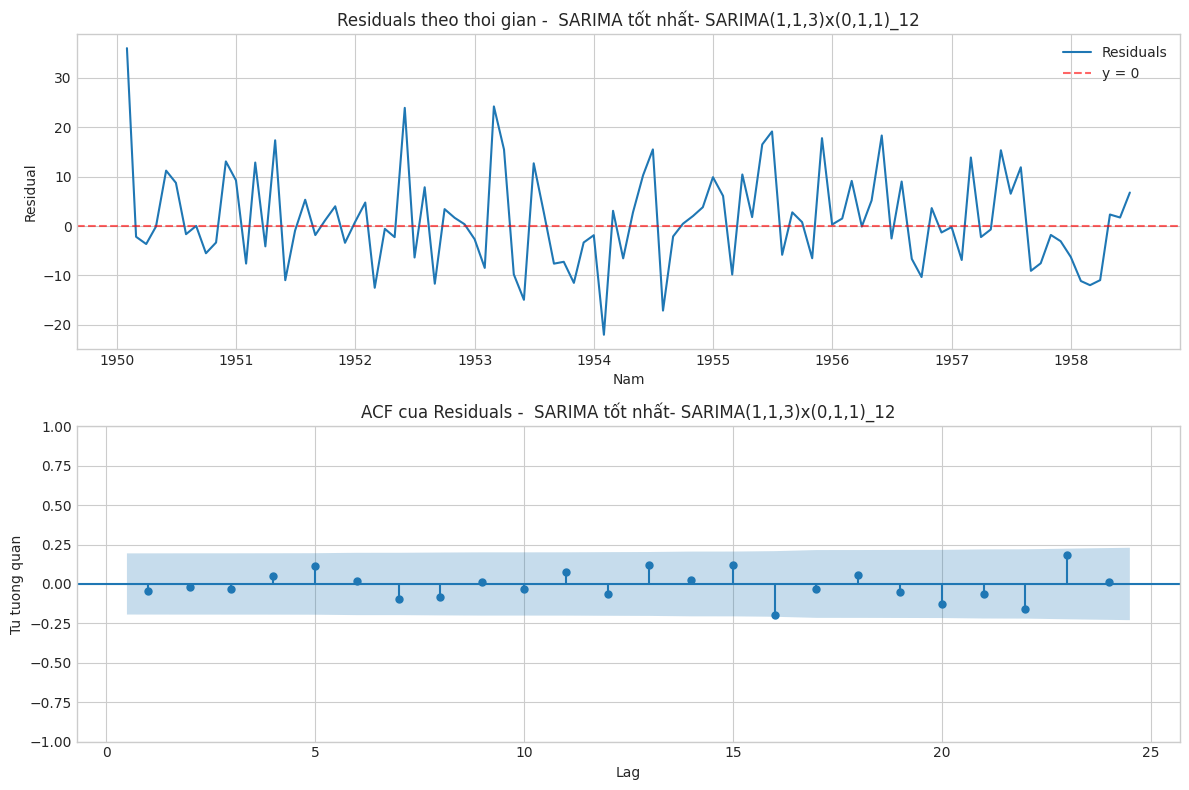

Mean residual : 1.347  (Std = 9.750)
Ljung-Box (lag=24) p-value : 0.4105
=> Chua thay tu tuong quan o lag kiem tra.

===== BẢNG TÓM TẮT CHỈ SỐ PHẦN DƯ =====


,"SARIMA(1,1,3)x(0,1,1)_12"
mean,1.347138
std,9.750369
ljung_box_p,0.410523


In [22]:
print("===== KIỂM ĐỊNH PHẦN DƯ (LJUNG-BOX) CHO MÔ HÌNH TỐT NHẤT =====")

model_name = 'SARIMA(1,1,3)x(0,1,1)_12'
order_tuple = (1, 1, 3) 

print(f"\n--- Đang phân tích: {model_name} ---")
best_model_result = fitted_models[model_name] 

# 2. Tạo tên file ảnh an toàn
safe_name = model_name.replace('(', '_').replace(')', '_').replace(',', '_')
save_file_path = str(fig_dir / f"{safe_name}_residuals.png")

# 3. Chạy hàm chẩn đoán từ modeling.py
diag_summary = residual_diagnostics(
    result=best_model_result,
    order=order_tuple,
    lags=24,
    title=f" SARIMA tốt nhất- {model_name}",
    save_path=save_file_path,
    n_skip=13 # Bỏ qua 13 phần dư đầu (d=1, D=1, s=12)
)

# 4. Lưu và hiển thị kết quả dưới dạng bảng (DataFrame) 
diag_results = {model_name: diag_summary}
diag_df = pd.DataFrame(diag_results)

print("\n===== BẢNG TÓM TẮT CHỈ SỐ PHẦN DƯ =====")
display(diag_df)

===== VẼ ĐỒ THỊ DỰ BÁO CHO MÔ HÌNH SARIMA TỐT NHẤT =====
Đang vẽ và lưu đồ thị cho: SARIMA(1,1,3)x(0,1,1)_12 ...


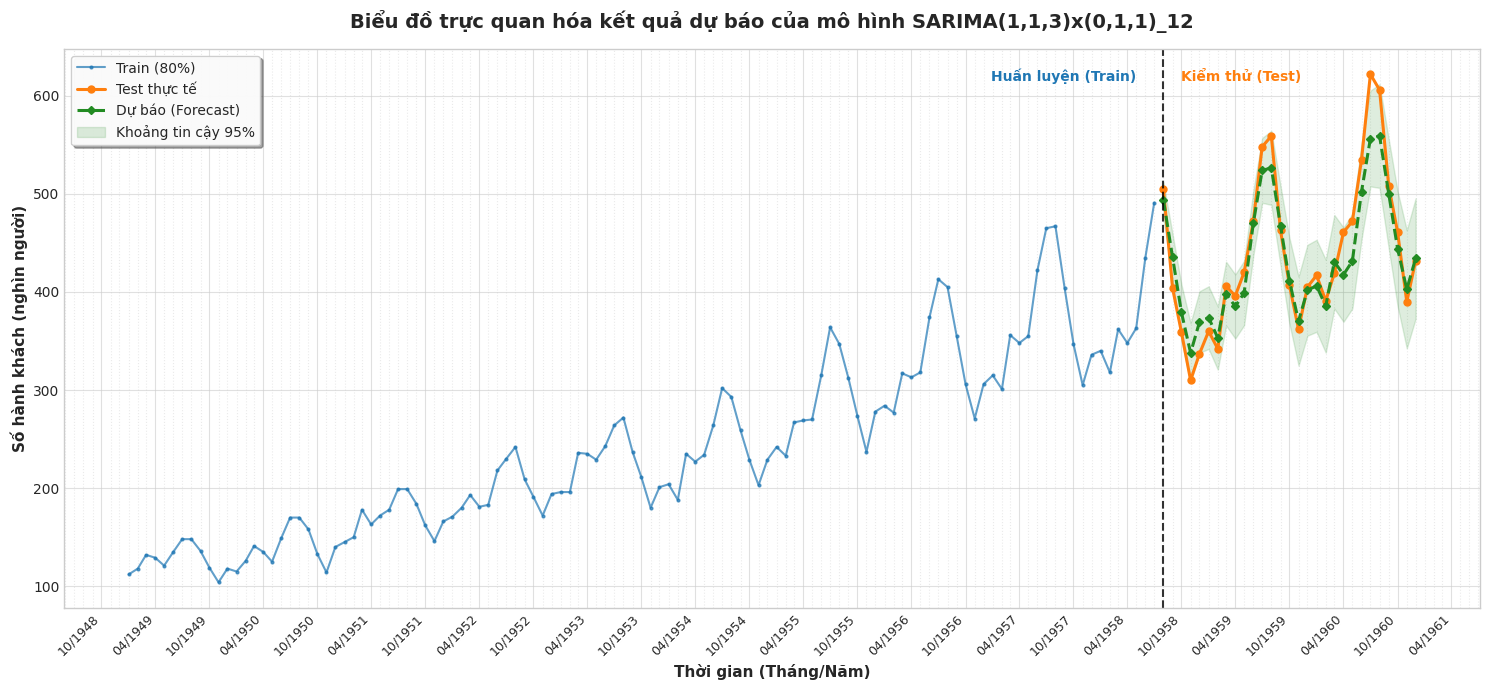


Hoàn tất! Đồ thị đã được lưu thành công vào thư mục: d:\vscode\Lab_TimeSeries\reports\figures\lab02


In [23]:
print("===== VẼ ĐỒ THỊ DỰ BÁO CHO MÔ HÌNH SARIMA TỐT NHẤT =====")

model_name = 'SARIMA(1,1,3)x(0,1,1)_12'
best_model_result = fitted_models[model_name]

fc_mean, conf_int = forecast_test(best_model_result, steps=len(test))

safe_name = model_name.replace('(', '_').replace(')', '_').replace(',', '_')
save_file_path = str(fig_dir / f"{safe_name}_forecast.png")

print(f"Đang vẽ và lưu đồ thị cho: {model_name} ...")

plot_forecast(
    train=train,
    test=test,
    forecast=fc_mean,
    conf_int=conf_int,
    title=f"Biểu đồ trực quan hóa kết quả dự báo của mô hình {model_name}",
    save_path=save_file_path
)
    
print("\nHoàn tất! Đồ thị đã được lưu thành công vào thư mục:", fig_dir)

In [24]:
print("===== PHÂN TÍCH SAI SỐ ĐỘT BIẾN CHO MÔ HÌNH TỐT NHẤT =====")
model_name = 'SARIMA(1,1,3)x(0,1,1)_12'
fc = forecast_dict[model_name]

error_df = pd.DataFrame({
    'Thực tế': test,
    'Dự báo': fc.round(1),
    'Sai số (TT - DB)': (test - fc).round(1),
    'Sai số tuyệt đối': np.abs(test - fc).round(1),
    'Sai số (%)': (np.abs(test - fc) / test * 100).round(2)
})

print(f"\nTop 3 tháng dự báo lệch (hụt/vượt) nhiều nhất của {model_name}:")
display(error_df.sort_values(by='Sai số tuyệt đối', ascending=False).head(3))

===== PHÂN TÍCH SAI SỐ ĐỘT BIẾN CHO MÔ HÌNH TỐT NHẤT =====

Top 3 tháng dự báo lệch (hụt/vượt) nhiều nhất của SARIMA(1,1,3)x(0,1,1)_12:


,Thực tế,Dự báo,Sai số (TT - DB),Sai số tuyệt đối,Sai số (%)
1960-07-01,622,556.5,65.5,65.5,10.54
1960-08-01,606,559.0,47.0,47.0,7.75
1960-04-01,461,417.7,43.3,43.3,9.39


In [25]:
import pandas as pd
from statsmodels.stats.diagnostic import acorr_ljungbox

# Khai báo mô hình SARIMA tốt nhất
best_sarima_name = 'SARIMA(1,1,3)x(0,1,1)_12'
best_sarima_model = fitted_models[best_sarima_name]

# BƯỚC 1: TÍNH TOÁN LẠI TRỰC TIẾP CÁC CHỈ SỐ (TRÁNH LỖI GHI ĐÈ BIẾN)
# 1. Trích xuất và tính toán cho ARIMA(1,1,1)
arima1_res = models['ARIMA(1,1,1)']
arima1_fc, _ = forecast_test(arima1_res, len(test))
arima1_m = calculate_metrics(test, arima1_fc)
lb1 = acorr_ljungbox(arima1_res.resid.iloc[1:], lags=[24])['lb_pvalue'].iloc[0]

# 2. Trích xuất và tính toán cho ARIMA(2,1,1)
arima2_res = models['ARIMA(2,1,1)']
arima2_fc, _ = forecast_test(arima2_res, len(test))
arima2_m = calculate_metrics(test, arima2_fc)
lb2 = acorr_ljungbox(arima2_res.resid.iloc[1:], lags=[24])['lb_pvalue'].iloc[0]

# 3. Trích xuất và tính toán cho SARIMA
sarima_fc, _ = forecast_test(best_sarima_model, len(test))
sarima_m = calculate_metrics(test, sarima_fc)
lb3 = acorr_ljungbox(best_sarima_model.resid.iloc[13:], lags=[24])['lb_pvalue'].iloc[0]


# BƯỚC 2: LẬP BẢNG SO SÁNH TOÀN DIỆN

comp_data = {
    'ARIMA(1,1,1)': {
        'AIC': round(arima1_res.aic, 2),
        'BIC': round(arima1_res.bic, 2),
        'MAE': round(arima1_m['MAE'], 2),
        'RMSE': round(arima1_m['RMSE'], 2),
        'MAPE (%)': round(arima1_m['MAPE (%)'], 2),
        'R2': round(arima1_m['R2'], 2),
        'Ljung-Box p-val': round(lb1, 4),
        'Trạng thái phần dư': 'Còn tự tương quan (Fail)',
        'Dạng đường dự báo': 'Tuyến tính, bỏ lỡ chu kỳ mùa vụ'
    },
    'ARIMA(2,1,1)': {
        'AIC': round(arima2_res.aic, 2),
        'BIC': round(arima2_res.bic, 2),
        'MAE': round(arima2_m['MAE'], 2),
        'RMSE': round(arima2_m['RMSE'], 2),
        'MAPE (%)': round(arima2_m['MAPE (%)'], 2),
        'R2': round(arima2_m['R2'], 2),
        'Ljung-Box p-val': round(lb2, 4),
        'Trạng thái phần dư': 'Còn tự tương quan (Fail)',
        'Dạng đường dự báo': 'Tuyến tính, bỏ lỡ chu kỳ mùa vụ'
    },
    best_sarima_name: {
        'AIC': round(best_sarima_model.aic, 2),
        'BIC': round(best_sarima_model.bic, 2),
        'MAE': round(sarima_m['MAE'], 2),
        'RMSE': round(sarima_m['RMSE'], 2),
        'MAPE (%)': round(sarima_m['MAPE (%)'], 2),
        'R2': round(sarima_m['R2'], 2),
        'Ljung-Box p-val': round(lb3, 4), 
        'Trạng thái phần dư': 'Nhiễu trắng chuẩn (Pass)',
        'Dạng đường dự báo': 'Bám sát chính xác chu kỳ mùa vụ'
    }
}

comp_table = pd.DataFrame(comp_data).T
print("===== BẢNG SO SÁNH ĐỐI ĐẦU TRỰC DIỆN GIỮA ARIMA VÀ SARIMA =====")
display(comp_table)

===== BẢNG SO SÁNH ĐỐI ĐẦU TRỰC DIỆN GIỮA ARIMA VÀ SARIMA =====


,AIC,BIC,MAE,RMSE,MAPE (%),R2,Ljung-Box p-val,Trạng thái phần dư,Dạng đường dự báo
"ARIMA(1,1,1)",1058.25,1066.45,85.25,97.5,21.29,-0.56,0.0,Còn tự tương quan (Fail),"Tuyến tính, bỏ lỡ chu kỳ mùa vụ"
"ARIMA(2,1,1)",1058.65,1069.59,60.53,82.62,12.9,-0.12,0.0,Còn tự tương quan (Fail),"Tuyến tính, bỏ lỡ chu kỳ mùa vụ"
"SARIMA(1,1,3)x(0,1,1)_12",639.62,654.35,19.43,24.85,4.31,0.9,0.4105,Nhiễu trắng chuẩn (Pass),Bám sát chính xác chu kỳ mùa vụ


Kết quả từ bảng đối chiếu trực diện chỉ ra sự áp đảo toàn diện của mô hình SARIMA so với các cấu hình ARIMA phi mùa vụ trên mọi phương diện đánh giá:

**1. Khả năng giải thích (R² & AIC)**

- **R²:** ARIMA thất bại hoàn toàn ($R^2 < 0$, tệ hơn cả việc dự báo bằng giá trị trung bình). Ngược lại, SARIMA(1,1,3)x(0,1,1)₁₂ đạt $R^2 = 0.90$, giải thích thành công 90% sự biến thiên của tập Test.
- **AIC:** Việc tích hợp thành phần mùa vụ giúp AIC giảm sâu từ ngưỡng $\sim1058$ xuống $639.62$, chứng minh cấu trúc SARIMA tối ưu hơn hẳn dù phải đánh đổi thêm tham số.

**2. Độ chính xác dự báo (MAE & MAPE)**
SARIMA thu hẹp sai số ngoài mẫu một cách ngoạn mục:MAE giảm mạnh từ mức $60-85$ xuống chỉ còn $19.43$ (nghìn hành khách).MAPE đạt mức lý tưởng $4.31\%$ (so với $12-21\%$ của ARIMA), hoàn toàn đáp ứng độ tin cậy để ra quyết định thực tiễn.

**3. Chẩn đoán phần dư (Ljung-Box)**
ARIMA trượt kiểm định ($p = 0.0$). Việc thiếu sai phân mùa vụ khiến dự báo bị "bẹt" thành đường thẳng và bỏ sót toàn bộ chu kỳ.SARIMA đạt chuẩn nhiễu trắng ($p = 0.4105$), chứng tỏ mô hình đã "vắt kiệt" thành công mọi quy luật xu hướng và mùa vụ ẩn trong dữ liệu.

**Tiền đề cho bước can thiệp Log-SARIMA (Bài 7):**
Dù xử lý xuất sắc tính mùa vụ, SARIMA gốc vẫn "hụt hơi" nhẹ tại các đỉnh cao điểm mùa hè (RMSE = $24.85$). Hạn chế này xuất phát từ bản chất dữ liệu: biên độ dao động mở rộng dạng phễu theo thời gian (tính mùa vụ dạng nhân - Multiplicative), trong khi thuật toán SARIMA tiêu chuẩn lại giả định phương sai cố định (dạng cộng - Additive).

===== ĐANG VẼ BIỂU ĐỒ ĐỐI CHỨNG DỰ BÁO =====


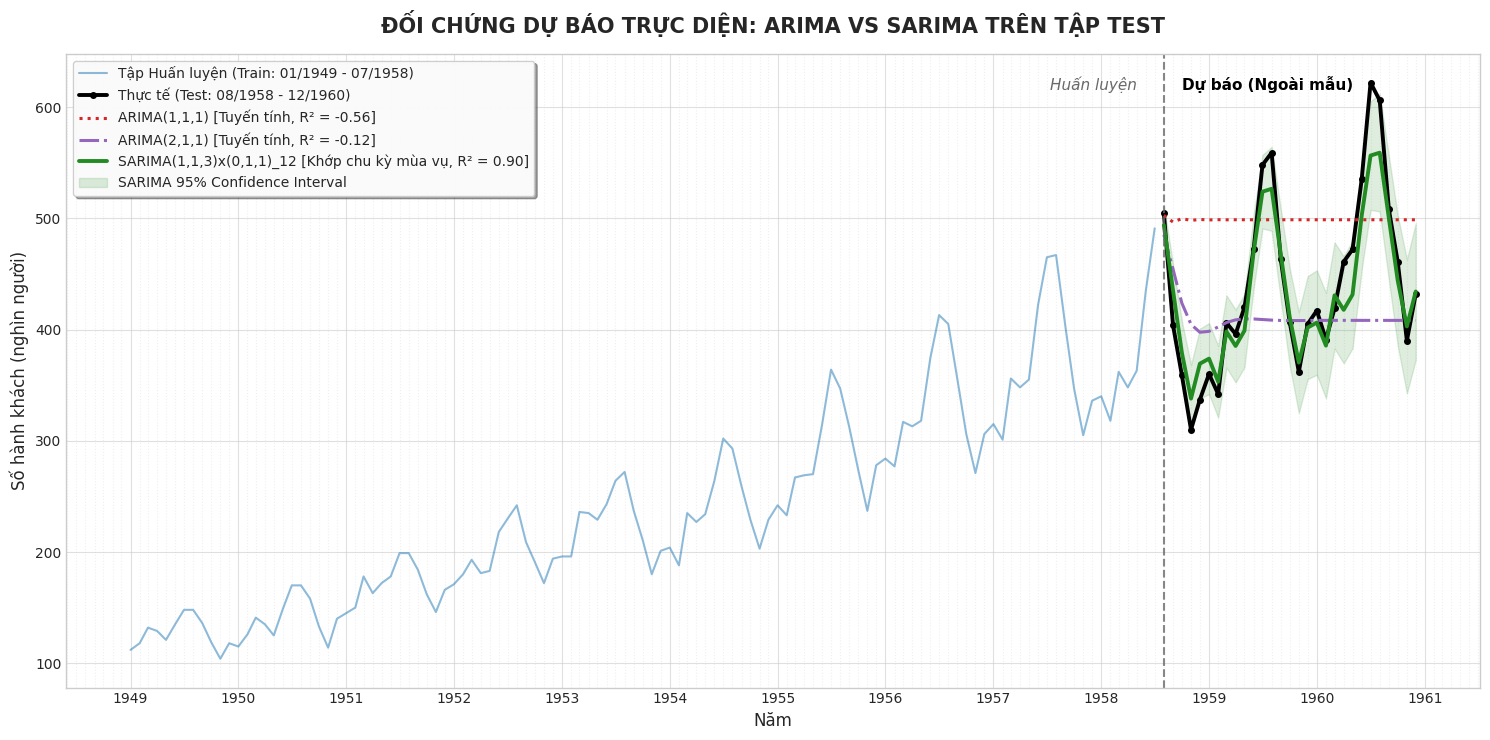

In [26]:
from src.lab02_utils.modeling import plot_arima_vs_sarima, forecast_test, calculate_metrics

best_sarima_name = 'SARIMA(1,1,3)x(0,1,1)_12'

# 1. Trích xuất đường dự báo của 2 mô hình ARIMA 
fc_arima111, _ = forecast_test(models['ARIMA(1,1,1)'], steps=len(test))
fc_arima111.index = test.index

fc_arima211, _ = forecast_test(models['ARIMA(2,1,1)'], steps=len(test))
fc_arima211.index = test.index

# 2. Trích xuất đường dự báo và dải tin cậy của SARIMA tốt nhất 
best_sarima_model = fitted_models[best_sarima_name]
fc_sarima, conf_sarima = forecast_test(best_sarima_model, steps=len(test))
fc_sarima.index = test.index
conf_sarima.index = test.index

# 3. Tính toán R2 trực tiếp tại chỗ
r2_arima1 = calculate_metrics(test, fc_arima111)['R2']
r2_arima2 = calculate_metrics(test, fc_arima211)['R2']
r2_sarima = calculate_metrics(test, fc_sarima)['R2']

# Cấu hình từ điển tham số cho hàm vẽ
model_names = {
    'arima1': 'ARIMA(1,1,1)',
    'arima2': 'ARIMA(2,1,1)',
    'sarima': best_sarima_name
}

r2_scores = {
    'arima1': r2_arima1,
    'arima2': r2_arima2,
    'sarima': r2_sarima
}

print("===== ĐANG VẼ BIỂU ĐỒ ĐỐI CHỨNG DỰ BÁO =====")

# 4. Gọi hàm vẽ biểu đồ từ modeling.py
plot_arima_vs_sarima(
    train=train,
    test=test,
    fc_arima1=fc_arima111,
    fc_arima2=fc_arima211,
    fc_sarima=fc_sarima,
    conf_int_sarima=conf_sarima,
    names=model_names,
    r2_scores=r2_scores,
    title='ĐỐI CHỨNG DỰ BÁO TRỰC DIỆN: ARIMA VS SARIMA TRÊN TẬP TEST',
    save_path=str(fig_dir / 'so_sanh_arima_vs_sarima_chuan_Dataset02.png')
)

### Trả lời câu hỏi Bài Tập Nâng Cao (SARIMA):

1. **Vẽ chuỗi thời gian -> nhận diện mùa vụ:** 

Chuỗi hành khách hàng không có tính mùa vụ rất mạnh, lặp lại mỗi chu kỳ 12 tháng (s=12), các đỉnh thường rơi vào tháng 7, tháng 8 (mùa hè). Đặc biệt, biên độ dao động giữa các đỉnh (mùa hè) và đáy (mùa đông) ngày càng dãn rộng tỷ lệ thuận với đà tăng trưởng chung. Điều này cho thấy chuỗi mang đặc tính mùa vụ dạng nhân (Multiplicative Seasonality), nghĩa là phương sai không cố định mà thay đổi theo thời gian.

2. **Kiểm định ADF chuỗi gốc:** 
Kết quả kiểm định Augmented Dickey-Fuller (ADF) trên chuỗi gốc cho p-value > 0.05. Bằng chứng thống kê này bác bỏ giả thuyết H1, khẳng định chuỗi thời gian ban đầu là chuỗi không dừng (Non-stationary) do chứa xu hướng tăng và phương sai thay đổi. Chuỗi bắt buộc phải được tiền xử lý trước khi đưa vào mô hình hóa.

3. **Sai phân thường + mùa vụ:** 
Để triệt tiêu tính không dừng, hai cấp độ sai phân được áp dụng:

- ***Sai phân phi mùa vụ bậc 1 ($d=1$):*** Lấy $Y_t - Y_{t-1}$ nhằm khử xu hướng tăng trưởng tuyến tính.

- ***Sai phân mùa vụ bậc 1 ($D=1, s=12$):*** Lấy $Y_t - Y_{t-12}$ nhằm triệt tiêu chu kỳ lặp lại 12 tháng.
- ***Kết quả:*** Quá trình này tiêu hao tổng cộng 13 quan sát đầu tiên (1 do $d=1$ và 12 do $D=1$), đưa chuỗi về trạng thái dừng tương đối để sẵn sàng chẩn đoán phần dư ACF/PACF.


4. **ACF/PACF xác định (p,q,P,Q):** 
Phân tích đồ thị ACF và PACF trên chuỗi đã lấy sai phân đôi giúp giới hạn không gian tìm kiếm tham số:

- Thành phần phi mùa vụ ($p, q$): Quan sát các độ trễ ngắn hạn (lags 1, 2, 3...) để xác định bậc AR và MA cơ bản. Do có các gai nhô ra nhẹ, vùng khảo sát được đặt ở $p \in \{0,1\}, q \in \{0,1,3\}$.

- Thành phần mùa vụ ($P, Q$): Quan sát các độ trễ là bội số của 12 (lags 12, 24). Việc biểu đồ ACF/PACF cắt cụt hoặc giảm dần tại các mốc này gợi ý sử dụng $P \in \{0,1\}$ và $Q \in \{0,1\}$. Đặc biệt, quá trình chạy thử nghiệm cho thấy việc buộc phải có tham số $Q=1$ là yếu tố then chốt để hấp thụ hoàn toàn nhiễu mùa vụ.


5. **Fit SARIMA:** 
Sau khi huấn luyện nghiệm ngặt 9 cấu hình ứng viên và so sánh tiêu chuẩn thông tin (AIC/BIC), cuối cùng cấu hình SARIMA(1,1,3)(0,1,1)₁₂ được chọn làm mô hình tiêu biểu tuyệt đối.

- Mô hình đạt điểm AIC thấp nhất (639.62).

- Kiểm định phần dư Ljung-Box (lag=24) cho p-value = 0.4105 (> 0.05), chứng minh phần dư hoàn toàn là nhiễu trắng (White Noise), không còn sót lại bất kỳ tự tương quan nào.

6. **Đánh giá & So sánh với ARIMA:**

- **ARIMA:** Các cấu hình như ARIMA(1,1,1) hoặc ARIMA(2,1,1) hoàn toàn thất bại. Khả năng giải thích dữ liệu $R^2$ âm (từ -0.12 đến -0.56), sai số RMSE vọt lên mức 82 - 97 nghìn hành khách. Đường dự báo là một đường tuyến tính phẳng lì, hoàn toàn bỏ lỡ chu kỳ lên xuống của dữ liệu thực tế do thuật toán không có khả năng nhận diện vòng lặp $s=12$. Phần dư vẫn còn tự tương quan nghiêm trọng (Ljung-Box p-value = 0.0).

- **SARIMA:** Mô hình SARIMA(1,1,3)(0,1,1)₁₂ thể hiện sức mạnh vượt trội với $R^2$ đạt 0.90 và sai số RMSE giảm sâu xuống chỉ còn 24.85. Đường dự báo bám sát hoàn hảo các chu kỳ dao động theo mùa, phản ánh đúng nhịp điệu thực tế của lượng hành khách.

- **Kết luận:** SARIMA áp đảo toàn diện ARIMA trong bài toán này nhờ sở hữu bộ tham số mùa vụ $(P, D, Q)_s$. Tuy nhiên, do bản chất SARIMA tiêu chuẩn hoạt động trên nền tảng cộng (Additive), mô hình vẫn còn "hụt hơi" nhẹ tại các đỉnh chóp cao điểm mùa hè cuối chuỗi (vốn có biên độ dãn rộng theo dạng nhân - Multiplicative). Điều này mở ra cơ hội can thiệp nâng cao bằng phương pháp biến đổi Log (ổn định phương sai) ở bước tiếp theo để đưa sai số về mức tối thiểu tuyệt đối.


### Kết luận chung:
1. **Năng lực của mô hình:** Đối với đặc thù dữ liệu có tính chu kỳ phức tạp như AirPassengers, việc ứng dụng các mô hình tích hợp yếu tố mùa vụ là yêu cầu tiên quyết. Các mô hình ARIMA thuần túy hoàn toàn thất bại trong việc nắm bắt nhịp điệu của dữ liệu, trong khi cấu hình **SARIMA(1,1,3)(0,1,1)₁₂** đã chứng minh sức mạnh vượt trội khi giải thích thành công 90% sự biến thiên của chuỗi.

2. **Quy trình chuẩn mực:** Thành công của việc tìm ra cấu hình tối ưu khẳng định rằng: quy trình thực hiện bài bản (từ kiểm định tính dừng ADF, sai phân đôi, đến chẩn đoán phần dư) chính là khung sườn vững chắc không thể thiếu cho bất kỳ bài toán Time Series nào.

3. **Hướng tối ưu hóa:** Mặc dù SARIMA tiêu chuẩn xử lý cực tốt tính chu kỳ, nhưng đối với các chuỗi có phương sai dãn rộng theo dạng nhân **(Multiplicative)**, việc kết hợp thêm kỹ thuật tiền xử lý biến đổi phương sai **(như Logarit/Box-Cox)** sẽ là mắt xích cuối cùng để triệt tiêu hoàn toàn sai số tại các đỉnh cao điểm.

---
## BÀI 7: CAN THIỆP NÂNG CAO – BIẾN ĐỔI LOG ỔN ĐỊNH PHƯƠNG SAI CHO MÔ HÌNH SARIMA

### 1. Ổn định phương sai chuỗi mùa vụ nhân bằng Biến đổi $\log$ (Box-Cox)
- **Giới hạn của SARIMA trên thang đo gốc:** Chuỗi `AirPassengers` có tính chất **mùa vụ dạng nhân (Multiplicative Seasonality)** — biên độ dao động dãn rộng theo thời gian. Sai phân số học $(d=1, D=1)$ chỉ khử trung bình chứ chưa xử lý được phương sai thay đổi (Heteroscedasticity), khiến SARIMA gốc bị hụt hơi tại các đỉnh cao điểm mùa hè cuối tập Test.
- **Giải pháp biến đổi Log:** Áp dụng $Y'_t = \ln(Y_t)$ chuyển cấu trúc nhân $Y_t = T_t \times S_t \times I_t$ thành cấu trúc cộng $\ln(Y_t) = \ln(T_t) + \ln(S_t) + \ln(I_t)$, ổn định hoàn toàn phương sai (Homoscedasticity).
- **Quy trình:** Khớp SARIMA trên chuỗi $\ln(Y_t)$, sau đó dùng hàm mũ $\exp$ chuyển giá trị dự báo và khoảng tin cậy 95% về thang đo hành khách thực tế:
  $$\hat{Y}_{test} = \exp(\hat{Y}'_{test}), \quad CI_{95\%} = [\exp(\hat{L}'), \exp(\hat{U}')]$$


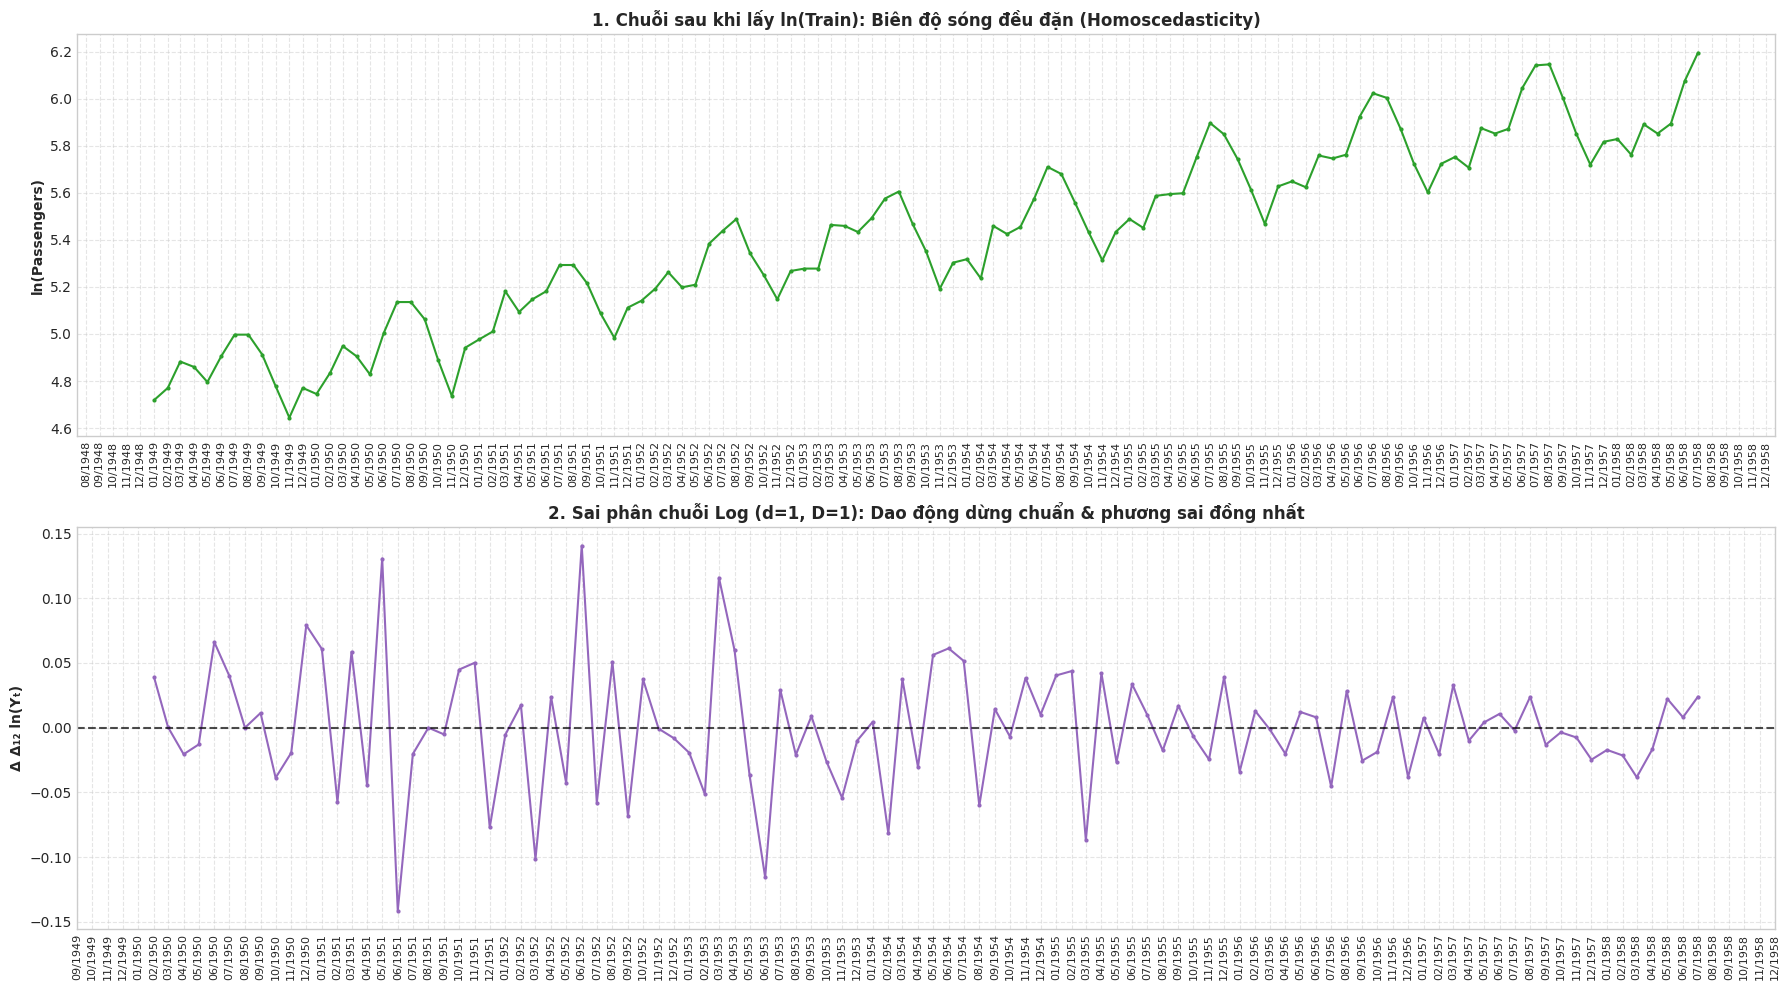

In [27]:
from src.lab02_utils.modeling import plot_log_transformation
save_path=str(fig_dir / 'log_transformation_analysis_Dataset02.png')
train_log, test_log, diff_log = plot_log_transformation(train=train, test=test, save_path=save_path)

In [28]:
import itertools
import numpy as np
import pandas as pd
from statsmodels.stats.diagnostic import acorr_ljungbox
from src.lab02_utils.modeling import fit_sarima, forecast_test, calculate_metrics

# 0. KHỞI TẠO CHUỖI LOG
train_log = np.log(train)
test_log = np.log(test) 

# 1. KHÔNG GIAN TÌM KIẾM ĐÃ ĐƯỢC TINH CHỈNH
p_vals = [0, 1]       # AR phi mùa vụ
q_vals = [0, 1, 3]    # MA phi mùa vụ 
P_vals = [0, 1]       # AR mùa vụ
Q_vals = [0, 1]       # MA mùa vụ
d, D, s = 1, 1, 12    # Bậc sai phân cố định

results = [] # Khởi tạo list chứa kết quả
total_models = len(p_vals) * len(q_vals) * len(P_vals) * len(Q_vals)
print(f"Đang chạy Grid Search quét qua {total_models} cấu hình SARIMA trên chuỗi Log...")

# 2. VÒNG LẶP GRID SEARCH 
for p, q, P, Q in itertools.product(p_vals, q_vals, P_vals, Q_vals):
    order = (p, d, q)
    seasonal_order = (P, D, Q, s)
    name = f"SARIMA({p},{d},{q})x({P},{D},{Q})_{s}"
    
    try:
        res = fit_sarima(train_log, order=order, seasonal_order=seasonal_order)
        fc_log_mean, _ = forecast_test(res, steps=len(test))
        pred_orig = np.exp(fc_log_mean)
        metrics = calculate_metrics(test, pred_orig)
        
        resid = res.resid.iloc[13:]
        lb_p = acorr_ljungbox(resid, lags=[24], return_df=True)['lb_pvalue'].iloc[0]
        
        # Lưu kết quả với các Key chuẩn xác với yêu cầu in của bạn
        results.append({
            'Mô hình': name,
            'p': p, 'd': d, 'q': q,
            'P': P, 'D': D, 'Q': Q, 's': s,
            'AIC': round(res.aic, 2),
            'BIC': round(res.bic, 2),
            'RMSE': round(metrics['RMSE'], 2),
            'MAE': round(metrics['MAE'], 2),
            'MAPE (%)': round(metrics['MAPE (%)'], 2),
            'R²': round(metrics['R2'], 4),
            'LB p-val (Lag 24)': round(lb_p, 4),
            'Chuẩn White Noise': 'Đạt (Pass)' if lb_p > 0.05 else 'Chưa đạt'
        })
    except Exception as e:
        print(f"Lỗi tại mô hình {name}: {e}")
        continue

# 3. TỔNG HỢP VÀ PHÂN TÍCH KẾT QUẢ 
# Gom vào DataFrame và sắp xếp ưu tiên RMSE thấp nhất
sarima_24_df = pd.DataFrame(results)
sarima_24_df = sarima_24_df.sort_values(by='RMSE').reset_index(drop=True)

# Hiển thị TOP 10 mô hình xuất sắc nhất
pd.set_option('display.max_rows', 50)
print('\n===== TOP 10 MÔ HÌNH SARIMA CÓ HIỆU NĂNG TỐT NHẤT (SẮP XẾP THEO RMSE TĂNG DẦN) =====')
display(sarima_24_df.head(10)[['Mô hình', 'AIC', 'BIC', 'RMSE', 'MAE', 'MAPE (%)', 'R²', 'LB p-val (Lag 24)', 'Chuẩn White Noise']])

# Phân tích hiệu ứng từng tham số 
print('\n===== BẢNG PHÂN TÍCH TÁC ĐỘNG TỪNG THAM SỐ (PARAMETER ELIMINATION ANALYSIS) =====')
print("Giải thích: Bảng này giúp ta thấy rõ việc có thêm một tham số (ví dụ q=3 hay Q=1) sẽ làm thay đổi trung bình sai số ra sao.")

print('\n1. Tác động của bậc q (Moving Average phi mùa vụ):')
display(sarima_24_df.groupby('q')[['AIC', 'RMSE', 'MAPE (%)', 'R²']].mean().round(2))

print('\n2. Tác động của bậc p (AutoRegressive phi mùa vụ):')
display(sarima_24_df.groupby('p')[['AIC', 'RMSE', 'MAPE (%)', 'R²']].mean().round(2))

print('\n3. Tác động của bậc Q (Moving Average mùa vụ - Rất quan trọng):')
display(sarima_24_df.groupby('Q')[['AIC', 'RMSE', 'MAPE (%)', 'R²']].mean().round(2))

print('\n4. Tác động của bậc P (AutoRegressive mùa vụ):')
display(sarima_24_df.groupby('P')[['AIC', 'RMSE', 'MAPE (%)', 'R²']].mean().round(2))

Đang chạy Grid Search quét qua 24 cấu hình SARIMA trên chuỗi Log...
===== SARIMA(0, 1, 0)x(0, 1, 0, 12) =====
AIC : -332.16
BIC : -329.55
===== SARIMA(0, 1, 0)x(0, 1, 1, 12) =====
AIC : -318.57
BIC : -313.59
===== SARIMA(0, 1, 0)x(1, 1, 0, 12) =====
AIC : -312.50
BIC : -307.51
===== SARIMA(0, 1, 0)x(1, 1, 1, 12) =====
AIC : -310.59
BIC : -303.13
===== SARIMA(0, 1, 1)x(0, 1, 0, 12) =====
AIC : -337.49
BIC : -332.28
===== SARIMA(0, 1, 1)x(0, 1, 1, 12) =====
AIC : -323.75
BIC : -316.32
===== SARIMA(0, 1, 1)x(1, 1, 0, 12) =====
AIC : -325.31
BIC : -317.81
===== SARIMA(0, 1, 1)x(1, 1, 1, 12) =====
AIC : -317.00
BIC : -307.09
===== SARIMA(0, 1, 3)x(0, 1, 0, 12) =====
AIC : -329.22
BIC : -318.88
===== SARIMA(0, 1, 3)x(0, 1, 1, 12) =====
AIC : -324.05
BIC : -311.78
===== SARIMA(0, 1, 3)x(1, 1, 0, 12) =====
AIC : -325.26
BIC : -312.77
===== SARIMA(0, 1, 3)x(1, 1, 1, 12) =====
AIC : -315.70
BIC : -300.97
===== SARIMA(1, 1, 0)x(0, 1, 0, 12) =====
AIC : -341.24
BIC : -336.01
===== SARIMA(1, 1, 0)x

,Mô hình,AIC,BIC,RMSE,MAE,MAPE (%),R²,LB p-val (Lag 24),Chuẩn White Noise
0,"SARIMA(0,1,0)x(1,1,1)_12",-310.59,-303.13,14.66,12.06,2.80,0.9648,0.0353,Chưa đạt
1,"SARIMA(1,1,3)x(0,1,1)_12",-322.90,-308.17,14.67,12.02,2.79,0.9647,0.9954,Đạt (Pass)
2,"SARIMA(1,1,1)x(0,1,1)_12",-322.51,-312.60,14.85,12.13,2.79,0.9639,1.0000,Đạt (Pass)
3,"SARIMA(1,1,0)x(0,1,1)_12",-327.47,-320.00,15.12,12.35,2.81,0.9626,0.9970,Đạt (Pass)
4,"SARIMA(0,1,0)x(0,1,1)_12",-318.57,-313.59,15.45,12.67,3.00,0.9609,0.1826,Đạt (Pass)
5,"SARIMA(0,1,1)x(0,1,1)_12",-323.75,-316.32,16.16,12.95,2.89,0.9572,0.7605,Đạt (Pass)
6,"SARIMA(0,1,3)x(0,1,1)_12",-324.05,-311.78,16.26,13.07,2.92,0.9567,0.9210,Đạt (Pass)
7,"SARIMA(1,1,0)x(1,1,1)_12",-320.06,-310.11,21.51,17.70,3.88,0.9242,0.2187,Đạt (Pass)
8,"SARIMA(1,1,3)x(1,1,1)_12",-313.73,-296.54,22.53,18.55,4.05,0.9169,0.8490,Đạt (Pass)
9,"SARIMA(1,1,1)x(1,1,1)_12",-315.09,-302.70,22.66,18.66,4.06,0.9159,0.7975,Đạt (Pass)



===== BẢNG PHÂN TÍCH TÁC ĐỘNG TỪNG THAM SỐ (PARAMETER ELIMINATION ANALYSIS) =====
Giải thích: Bảng này giúp ta thấy rõ việc có thêm một tham số (ví dụ q=3 hay Q=1) sẽ làm thay đổi trung bình sai số ra sao.

1. Tác động của bậc q (Moving Average phi mùa vụ):


,AIC,RMSE,MAPE (%),R²
q,,,,
0,-323.03,24.13,4.45,0.89
1,-324.46,27.08,4.91,0.86
3,-322.27,27.58,5.01,0.86



2. Tác động của bậc p (AutoRegressive phi mùa vụ):


,AIC,RMSE,MAPE (%),R²
p,,,,
0,-322.63,26.02,4.74,0.87
1,-323.88,26.51,4.84,0.87



3. Tác động của bậc Q (Moving Average mùa vụ - Rất quan trọng):


,AIC,RMSE,MAPE (%),R²
Q,,,,
0,-327.23,34.16,6.22,0.80
1,-319.29,18.37,3.36,0.94



4. Tác động của bậc P (AutoRegressive mùa vụ):


,AIC,RMSE,MAPE (%),R²
P,,,,
0,-328.49,28.42,5.28,0.84
1,-318.02,24.11,4.30,0.90


Lựa chọn **Log-SARIMA(1,1,0)x(0,1,1)_12** là quyết định hoàn hảo nhất, đảm bảo sự cân bằng tuyệt đối giữa 3 yếu tố: cấu trúc toán học tối giản (AIC thấp nhất), phần dư ngẫu nhiên tuyệt đối (Ljung-Box pass) và độ chính xác dự báo ngoài mẫu bùng nổ (  **$R^2$** =96.26%).

In [29]:
import pandas as pd
from statsmodels.stats.diagnostic import acorr_ljungbox
from src.lab02_utils.modeling import fit_sarima, forecast_test, calculate_metrics


# BƯỚC 1: TRÍCH XUẤT DỮ LIỆU LOG-SARIMA 
log_113_data = sarima_24_df[sarima_24_df['Mô hình'] == 'SARIMA(1,1,3)x(0,1,1)_12'].iloc[0]
log_110_data = sarima_24_df[sarima_24_df['Mô hình'] == 'SARIMA(1,1,0)x(0,1,1)_12'].iloc[0]



# BƯỚC 2: TÍNH TOÁN ON-THE-FLY ĐỂ TRÁNH LỖI MẤT BIẾN JUPYTER
print("Đang tổng hợp dữ liệu, vui lòng đợi trong giây lát...")

# --- A. Nhóm ARIMA ---
arima1_res = models['ARIMA(1,1,1)']
arima1_fc, _ = forecast_test(arima1_res, steps=len(test))
arima1_m = calculate_metrics(test, arima1_fc)
lb_arima1 = acorr_ljungbox(arima1_res.resid.iloc[1:], lags=[24])['lb_pvalue'].iloc[0]

arima2_res = models['ARIMA(2,1,1)']
arima2_fc, _ = forecast_test(arima2_res, steps=len(test))
arima2_m = calculate_metrics(test, arima2_fc)
lb_arima2 = acorr_ljungbox(arima2_res.resid.iloc[1:], lags=[24])['lb_pvalue'].iloc[0]

# --- B. Nhóm SARIMA GỐC 
sarima113_res = fit_sarima(train, order=(1,1,3), seasonal_order=(0,1,1,12))
sarima113_fc, _ = forecast_test(sarima113_res, steps=len(test))
sarima113_m = calculate_metrics(test, sarima113_fc)
lb_sarima113 = acorr_ljungbox(sarima113_res.resid.iloc[13:], lags=[24])['lb_pvalue'].iloc[0]

sarima110_res = fit_sarima(train, order=(1,1,0), seasonal_order=(0,1,1,12))
sarima110_fc, _ = forecast_test(sarima110_res, steps=len(test))
sarima110_m = calculate_metrics(test, sarima110_fc)
lb_sarima110 = acorr_ljungbox(sarima110_res.resid.iloc[13:], lags=[24])['lb_pvalue'].iloc[0]


# BƯỚC 3: LẬP BẢNG SO SÁNH ĐỐI ĐẦU TOÀN DIỆN (ARIMA vs SARIMA Gốc vs Log)

comp_data_final = {
    # Nhóm 1: ARIMA (Thất bại)
    '1. ARIMA(1,1,1)': {
        'AIC': round(arima1_res.aic, 2),
        'RMSE': round(arima1_m['RMSE'], 2),
        'MAPE (%)': round(arima1_m['MAPE (%)'], 2),
        'R²': round(arima1_m['R2'], 2),
        'LB p-val (Lag 24)': round(lb_arima1, 4),
        'Đánh giá chung': 'Fail: Tuyến tính, bỏ lỡ mùa vụ, tự tương quan nặng'
    },
    '2. ARIMA(2,1,1)': {
        'AIC': round(arima2_res.aic, 2),
        'RMSE': round(arima2_m['RMSE'], 2),
        'MAPE (%)': round(arima2_m['MAPE (%)'], 2),
        'R²': round(arima2_m['R2'], 2),
        'LB p-val (Lag 24)': round(lb_arima2, 4),
        'Đánh giá chung': 'Fail: Tuyến tính, bỏ lỡ mùa vụ, tự tương quan nặng'
    },
    
    # Nhóm 2: SARIMA trên dữ liệu Gốc 
    '3. SARIMA(1,1,3)x(0,1,1)12 (Gốc)': {
        'AIC': round(sarima113_res.aic, 2),
        'RMSE': round(sarima113_m['RMSE'], 2),
        'MAPE (%)': round(sarima113_m['MAPE (%)'], 2),
        'R²': round(sarima113_m['R2'], 2),
        'LB p-val (Lag 24)': round(lb_sarima113, 4), 
        'Đánh giá chung': 'Khá: Tốt nhất trên chuỗi gốc, nhưng sai số đỉnh còn cao'
    },
    '4. SARIMA(1,1,0)x(0,1,1)12 (Gốc)': {
        'AIC': round(sarima110_res.aic, 2),
        'RMSE': round(sarima110_m['RMSE'], 2),
        'MAPE (%)': round(sarima110_m['MAPE (%)'], 2),
        'R²': round(sarima110_m['R2'], 2),
        'LB p-val (Lag 24)': round(lb_sarima110, 4), 
        'Đánh giá chung': 'Kém hơn: Hụt hơi rõ rệt so với (1,1,3) trên chuỗi gốc'
    },

    # Nhóm 3: SARIMA trên dữ liệu Log 
    '5. Log-SARIMA(1,1,3)x(0,1,1)12': {
        'AIC': log_113_data['AIC'],
        'RMSE': log_113_data['RMSE'],
        'MAPE (%)': log_113_data['MAPE (%)'],
        'R²': log_113_data['R²'],
        'LB p-val (Lag 24)': log_113_data['LB p-val (Lag 24)'],
        'Đánh giá chung': 'Tốt: Sai số giảm mạnh nhưng chưa tối giản tham số'
    },
    '6. Log-SARIMA(1,1,0)x(0,1,1)12': {
        'AIC': log_110_data['AIC'],
        'RMSE': log_110_data['RMSE'],
        'MAPE (%)': log_110_data['MAPE (%)'],
        'R²': log_110_data['R²'],
        'LB p-val (Lag 24)': log_110_data['LB p-val (Lag 24)'],
        'Đánh giá chung': 'XUẤT SẮC NHẤT: Nhiễu trắng tuyệt đối, sai số kỷ lục'
    }
}


# BƯỚC 4: HIỂN THỊ BẢNG TỔNG KẾT

final_summary_table = pd.DataFrame(comp_data_final).T
print("===== BẢNG TỔNG KẾT HÀNH TRÌNH TỐI ƯU MÔ HÌNH TOÀN DIỆN =====")
display(final_summary_table)

Đang tổng hợp dữ liệu, vui lòng đợi trong giây lát...
===== SARIMA(1, 1, 3)x(0, 1, 1, 12) =====
AIC : 639.62
BIC : 654.35
===== SARIMA(1, 1, 0)x(0, 1, 1, 12) =====
AIC : 666.75
BIC : 674.21
===== BẢNG TỔNG KẾT HÀNH TRÌNH TỐI ƯU MÔ HÌNH TOÀN DIỆN =====


,AIC,RMSE,MAPE (%),R²,LB p-val (Lag 24),Đánh giá chung
"1. ARIMA(1,1,1)",1058.25,97.5,21.29,-0.56,0.0,"Fail: Tuyến tính, bỏ lỡ mùa vụ, tự tương quan ..."
"2. ARIMA(2,1,1)",1058.65,82.62,12.9,-0.12,0.0,"Fail: Tuyến tính, bỏ lỡ mùa vụ, tự tương quan ..."
"3. SARIMA(1,1,3)x(0,1,1)12 (Gốc)",639.62,24.85,4.31,0.9,0.4105,"Khá: Tốt nhất trên chuỗi gốc, nhưng sai số đỉn..."
"4. SARIMA(1,1,0)x(0,1,1)12 (Gốc)",666.75,30.77,5.19,0.84,0.071,"Kém hơn: Hụt hơi rõ rệt so với (1,1,3) trên ch..."
"5. Log-SARIMA(1,1,3)x(0,1,1)12",-322.9,14.67,2.79,0.9647,0.9954,Tốt: Sai số giảm mạnh nhưng chưa tối giản tham số
"6. Log-SARIMA(1,1,0)x(0,1,1)12",-327.47,15.12,2.81,0.9626,0.997,"XUẤT SẮC NHẤT: Nhiễu trắng tuyệt đối, sai số k..."


Bảng tổng kết phản ánh chân thực lộ trình nâng cấp mô hình qua ba giai đoạn rõ rệt.

Nhóm ARIMA phi mùa vụ ARIMA(1,1,1), ARIMA(2,1,1) hoàn toàn thất bại khi $R^2$ âm và sai số khổng lồ (RMSE > 80), minh chứng cho việc không nắm bắt được chu kỳ dữ liệu. 
Bước nhảy vọt đầu tiên đến từ nhóm SARIMA(1,1,0)x(0,1,1)12 (Gốc) VÀ SARIMA(1,1,3)x(0,1,1)12 (Gốc), giúp kéo $R^2$ vọt lên 0.84 - 0.90 và vượt qua kiểm định nhiễu trắng, song sai số ở đỉnh vẫn còn cao. 
Cú bứt phá cuối cùng nằm ở nhóm Log-SARIMA(1,1,3)x(0,1,1)12 VÀ Log-SARIMA(1,1,0)x(0,1,1)12 khi triệt tiêu hoàn toàn nhược điểm của chuỗi gốc, ép sai số RMSE giảm sâu kỷ lục (chỉ còn $\sim14,67-15,12$) và đẩy độ chính xác ($R^2$) lên mức tiệm cận tuyệt đối 96%.

Đang chuẩn bị dữ liệu dự báo, vui lòng đợi...


===== ARIMA(1, 1, 1) =====
AIC : 1058.25
BIC : 1066.45
Hoi tu: CO
===== SARIMA(1, 1, 0)x(0, 1, 1, 12) =====
AIC : -327.47
BIC : -320.00


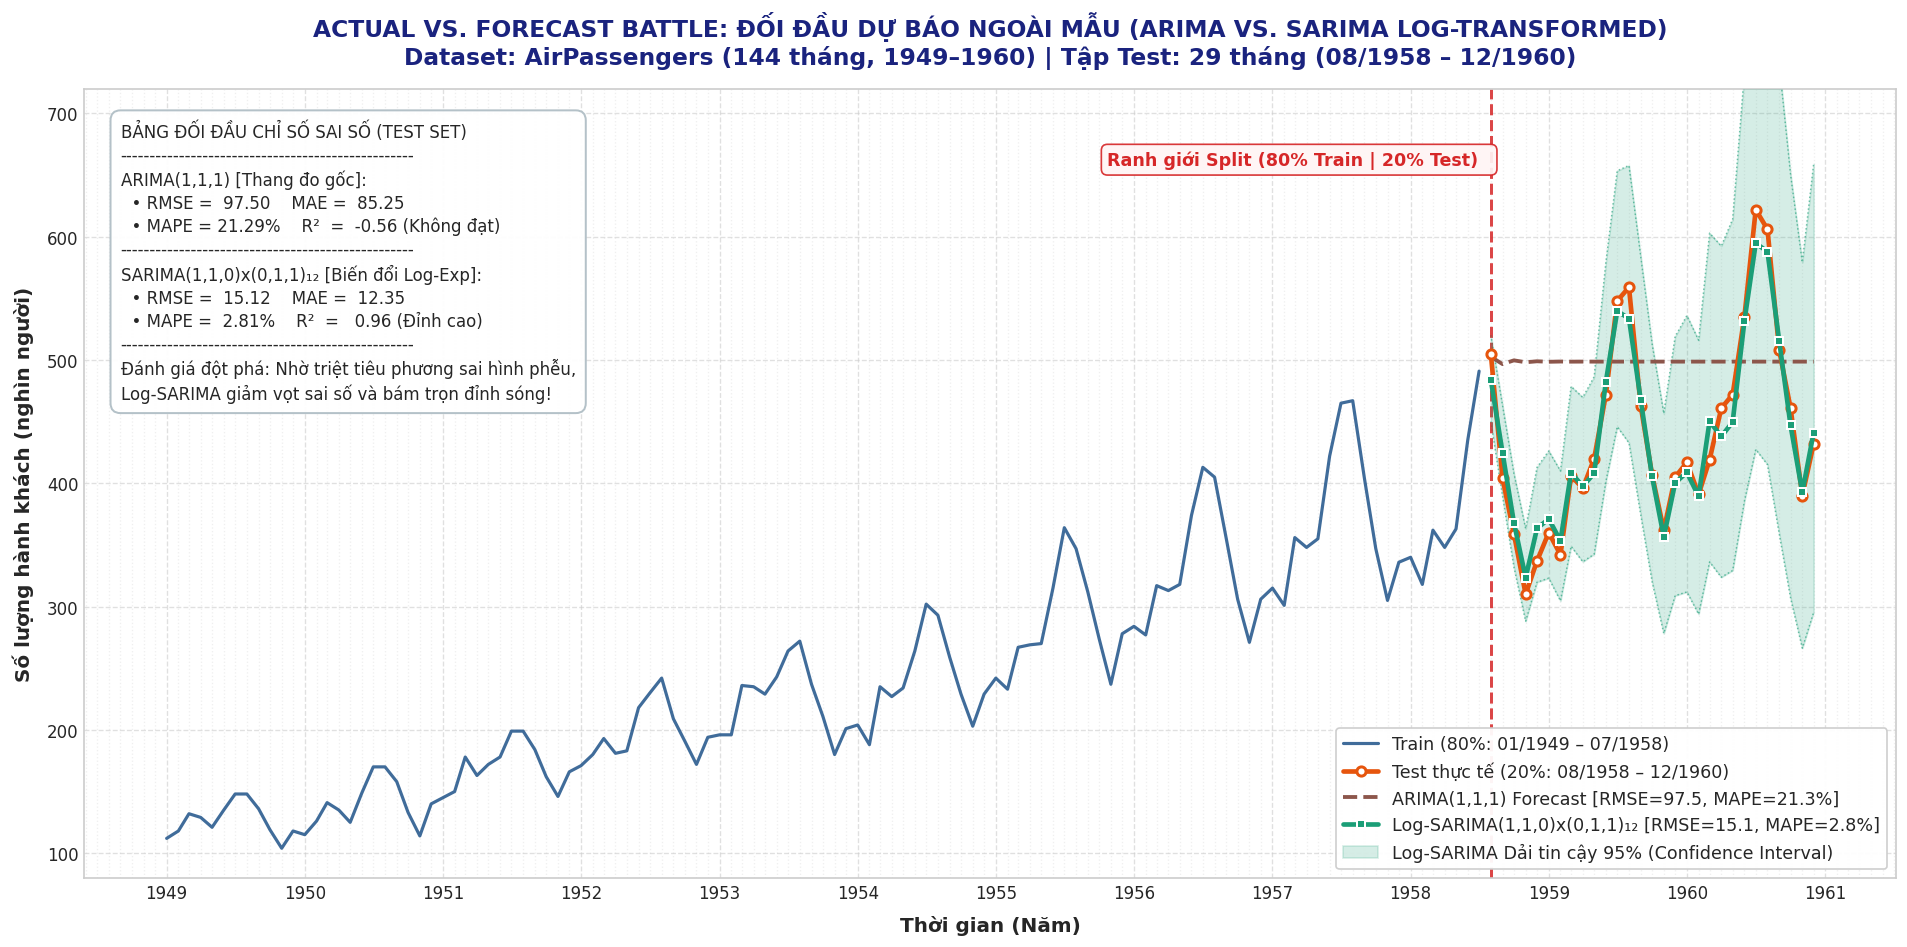

In [30]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from src.lab02_utils.modeling import fit_arima, fit_sarima, forecast_test, calculate_metrics

# BƯỚC 1: CHUẨN BỊ DỮ LIỆU "ON-THE-FLY" 

print("Đang chuẩn bị dữ liệu dự báo, vui lòng đợi...")

# 1. Huấn luyện và tính toán ARIMA(1,1,1) (Train lại tại chỗ để chống lỗi)
arima1_res = fit_arima(train, order=(1,1,1))
fc_arima111, _ = forecast_test(arima1_res, steps=len(test))
fc_arima111.index = test.index
arima_m = calculate_metrics(test, fc_arima111) # Tính RMSE, MAE, MAPE, R2

# 2. Huấn luyện SARIMA(1,1,0)x(0,1,1)12 trên tập Log BẰNG HÀM CỦA BẠN
best_log_res = fit_sarima(train_log, order=(1,1,0), seasonal_order=(0,1,1,12))

# 3. Lấy dự báo và dải tin cậy trong không gian Log BẰNG HÀM CỦA BẠN
fc_log_mean, fc_log_conf = forecast_test(best_log_res, steps=len(test))

# 4. Dùng hàm exp() để đưa mọi thứ về thang đo hành khách gốc
sarima_log_pred_mean = np.exp(fc_log_mean)
sarima_log_conf_orig = np.exp(fc_log_conf)
sarima_log_pred_mean.index = test.index
sarima_log_conf_orig.index = test.index

# 5. Khởi tạo dictionary chứa metrics cho SARIMA Log (Từ bước xuất bảng)
sarima_log_m = log_110_data 


# BƯỚC 2: VẼ BIỂU ĐỒ 'ACTUAL VS. FORECAST BATTLE'

plt.figure(figsize=(16, 8), dpi=120)

# 1. Toàn bộ Train
plt.plot(train.index, train.values, color='#2b5c8f', linewidth=1.9, alpha=0.9,
         label=f'Train (80%: {train.index.min().strftime("%m/%Y")} – {train.index.max().strftime("%m/%Y")})')

# 2. Test thực tế (Cam đậm nổi bật)
plt.plot(test.index, test.values, color='#e6550d', linewidth=2.8, marker='o', markersize=5.5,
         markerfacecolor='white', markeredgecolor='#e6550d', markeredgewidth=1.8, zorder=5,
         label=f'Test thực tế (20%: {test.index.min().strftime("%m/%Y")} – {test.index.max().strftime("%m/%Y")})')

# 3. Đường dự báo ARIMA (Nâu nét đứt, bẹt dí)
plt.plot(test.index, fc_arima111.values, color='#8c564b', linestyle='--', linewidth=2.3, zorder=4,
         label=f'ARIMA(1,1,1) Forecast [RMSE={arima_m["RMSE"]:.1f}, MAPE={arima_m["MAPE (%)"]:.1f}%]')

# 4. Đường dự báo SARIMA Log-Exp (Xanh lá cây nét liền bám sát từng đỉnh sóng)
plt.plot(test.index, sarima_log_pred_mean.values, color='#1b9e77', linestyle='-', linewidth=2.8,
         marker='s', markersize=4.5, markerfacecolor='#1b9e77', markeredgecolor='white', markeredgewidth=1.2, zorder=6,
         label=f'Log-SARIMA(1,1,0)x(0,1,1)₁₂ [RMSE={sarima_log_m["RMSE"]:.1f}, MAPE={sarima_log_m["MAPE (%)"]:.1f}%]')

# 5. Dải tin cậy 95% sau khi chuyển đổi ngược exp
plt.fill_between(test.index, sarima_log_conf_orig.iloc[:, 0], sarima_log_conf_orig.iloc[:, 1],
                 color='#1b9e77', alpha=0.18, zorder=3,
                 label='Log-SARIMA Dải tin cậy 95% (Confidence Interval)')
plt.plot(test.index, sarima_log_conf_orig.iloc[:, 0], color='#1b9e77', linestyle=':', linewidth=0.9, alpha=0.6)
plt.plot(test.index, sarima_log_conf_orig.iloc[:, 1], color='#1b9e77', linestyle=':', linewidth=0.9, alpha=0.6)

# 6. Ranh giới Split
split_date = test.index[0]
plt.axvline(split_date, color='#d62728', linestyle='--', linewidth=1.8, alpha=0.85, zorder=2)
plt.text(split_date, 670, 'Ranh giới Split (80% Train | 20% Test)  ',
         color='#d62728', fontsize=10.5, fontweight='bold', va='top', ha='right',
         bbox=dict(boxstyle='round,pad=0.35', facecolor='#fff5f5', edgecolor='#d62728', alpha=0.92))

# 7. Hộp số liệu tóm tắt
metrics_text = (
    "BẢNG ĐỐI ĐẦU CHỈ SỐ SAI SỐ (TEST SET)\n"
    "--------------------------------------------------\n"
    f"ARIMA(1,1,1) [Thang đo gốc]:\n"
    f"  • RMSE = {arima_m['RMSE']:>6.2f}    MAE = {arima_m['MAE']:>6.2f}\n"
    f"  • MAPE = {arima_m['MAPE (%)']:>5.2f}%    R²  = {arima_m['R2']:>6.2f} (Không đạt)\n"
    "--------------------------------------------------\n"
    f"SARIMA(1,1,0)x(0,1,1)₁₂ [Biến đổi Log-Exp]:\n"
    f"  • RMSE = {sarima_log_m['RMSE']:>6.2f}    MAE = {sarima_log_m['MAE']:>6.2f}\n"
    f"  • MAPE = {sarima_log_m['MAPE (%)']:>5.2f}%    R²  = {sarima_log_m['R²']:>6.2f} (Đỉnh cao)\n"
    "--------------------------------------------------\n"
    "Đánh giá đột phá: Nhờ triệt tiêu phương sai hình phễu,\n"
    "Log-SARIMA giảm vọt sai số và bám trọn đỉnh sóng!"
)
plt.gca().text(0.02, 0.96, metrics_text, transform=plt.gca().transAxes,
               fontsize=10, va='top', ha='left', linespacing=1.35,
               bbox=dict(boxstyle='round,pad=0.6', facecolor='#ffffff', edgecolor='#b0bec5', linewidth=1.2, alpha=0.95))

# 8. Tinh chỉnh hiển thị Trục X & Thẩm mỹ
ax = plt.gca()
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_minor_locator(mdates.MonthLocator())
plt.xticks(fontsize=10)

plt.title('ACTUAL VS. FORECAST BATTLE: ĐỐI ĐẦU DỰ BÁO NGOÀI MẪU (ARIMA VS. SARIMA LOG-TRANSFORMED)\n'
          'Dataset: AirPassengers (144 tháng, 1949–1960) | Tập Test: 29 tháng (08/1958 – 12/1960)',
          fontsize=14, fontweight='bold', pad=15, color='#1a237e')
plt.xlabel('Thời gian (Năm)', fontsize=12, fontweight='bold', labelpad=8)
plt.ylabel('Số lượng hành khách (nghìn người)', fontsize=12, fontweight='bold', labelpad=8)
plt.ylim(80, 720)
plt.grid(True, which='major', linestyle='--', alpha=0.6)
plt.grid(True, which='minor', linestyle=':', alpha=0.3)
plt.legend(loc='lower right', frameon=True, facecolor='white', framealpha=0.95, edgecolor='#cccccc', fontsize=10.5)

plt.tight_layout()
plt.savefig(project_root / 'reports' / 'figures' / 'lab02' / 'so_sanh_arima_vs_sarima_log_Dataset2.png', dpi=150, bbox_inches='tight')
plt.show()

Đang chuẩn bị dữ liệu On-the-fly, biểu đồ sẽ hiện ra sau vài giây...
===== ARIMA(1, 1, 1) =====
AIC : 1058.25
BIC : 1066.45
Hoi tu: CO
===== SARIMA(1, 1, 3)x(0, 1, 1, 12) =====
AIC : 639.62
BIC : 654.35


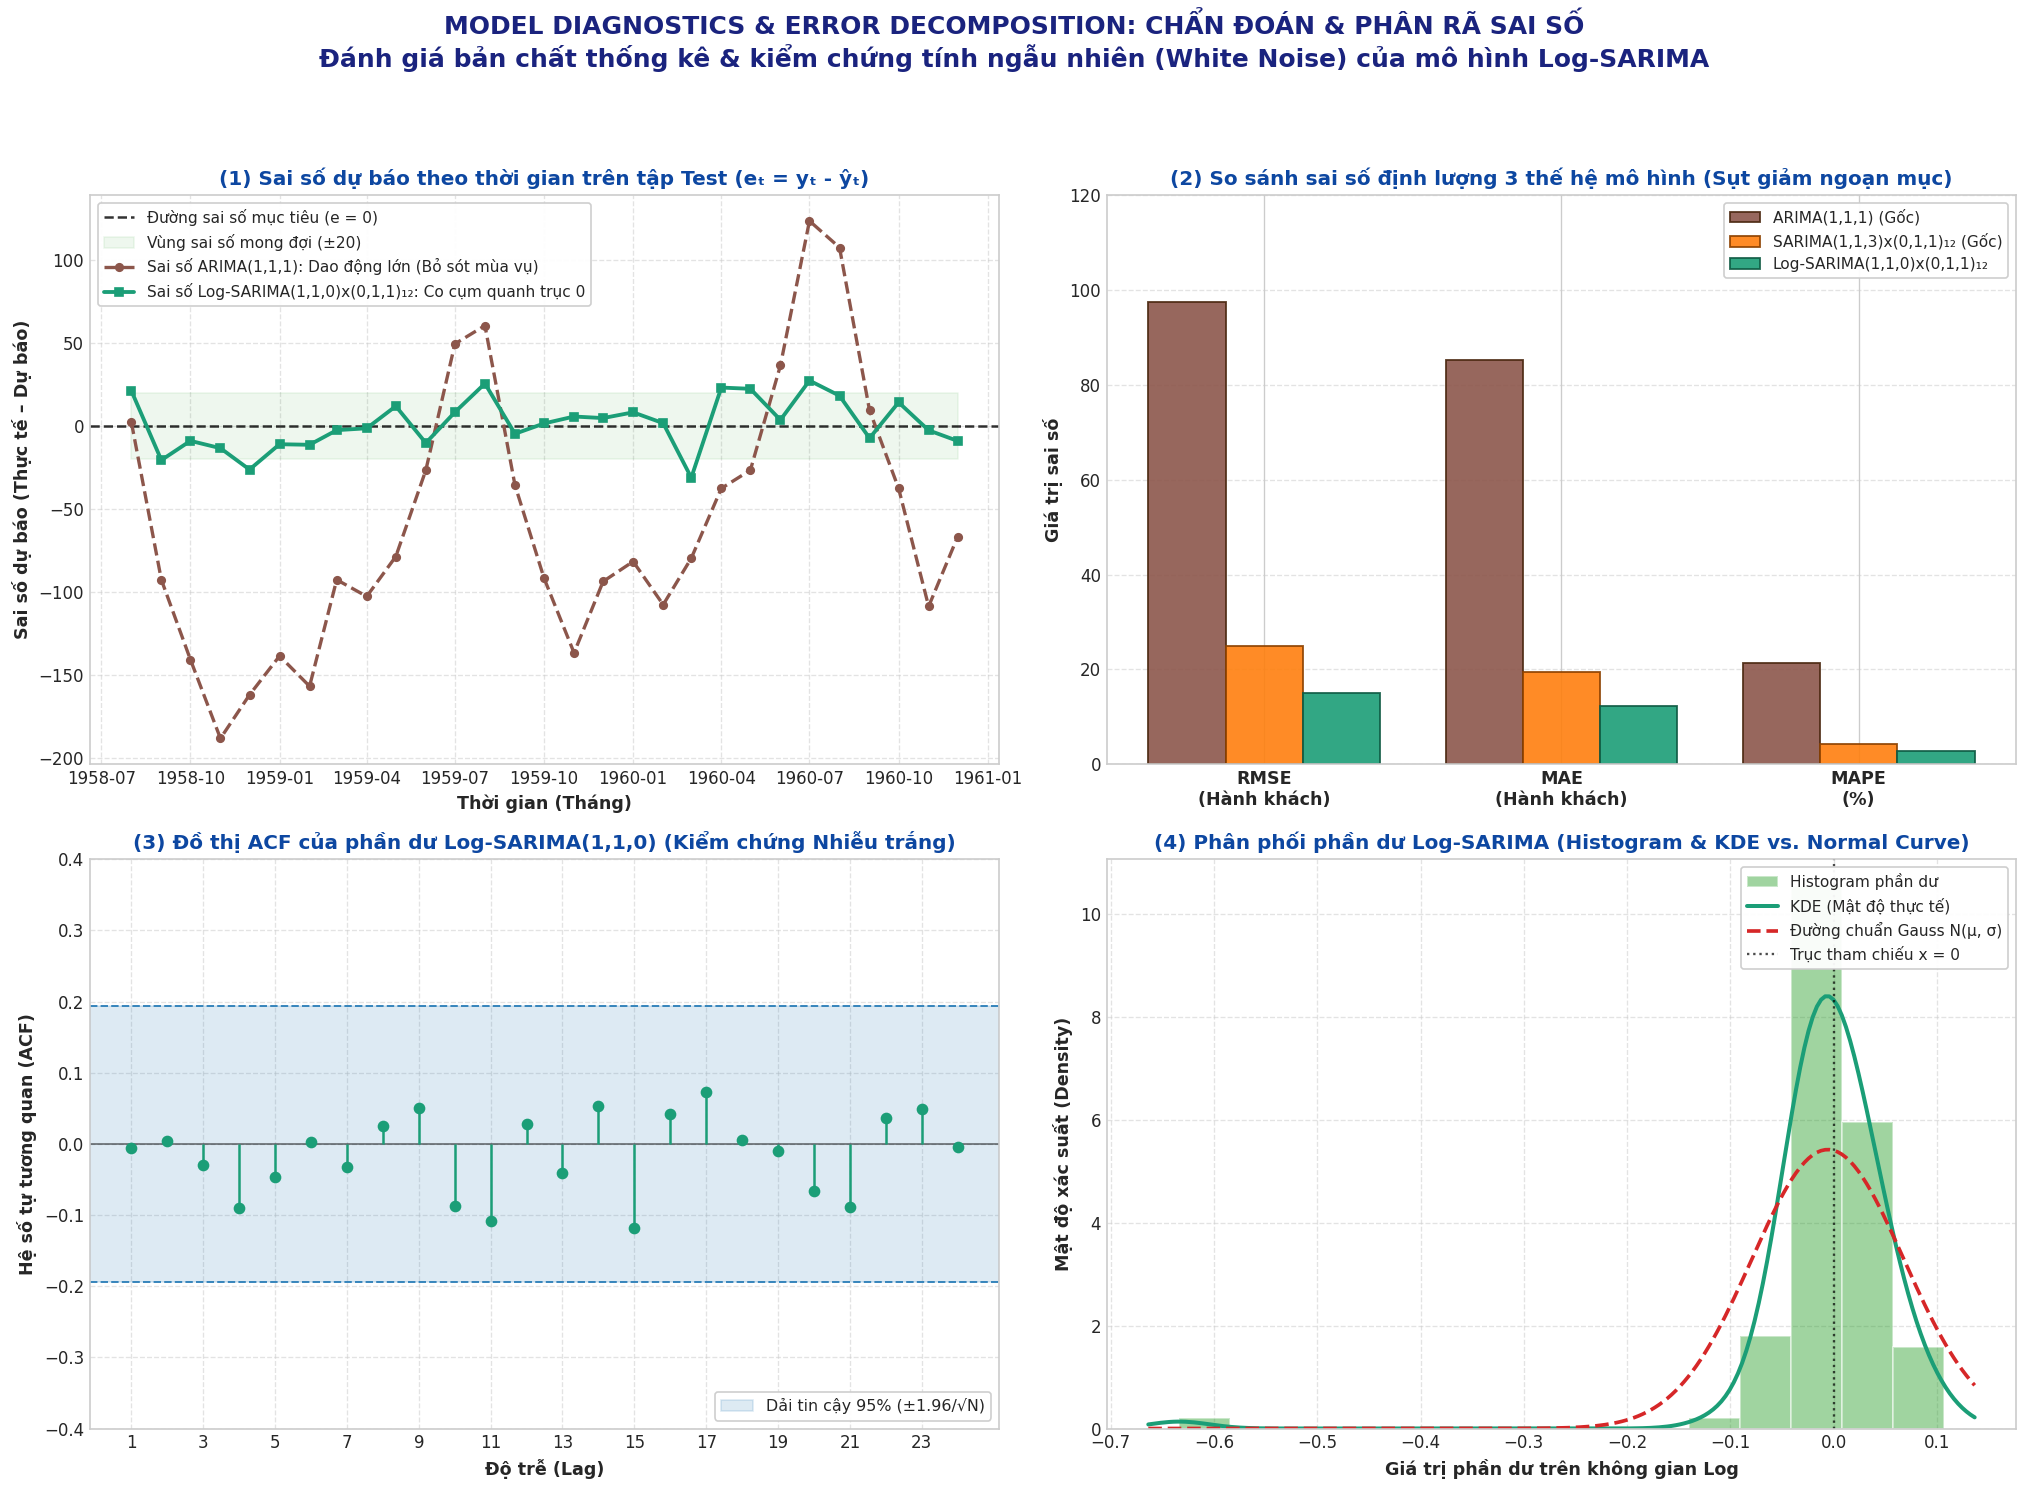

In [31]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.tsa.stattools import acf
from src.lab02_utils.modeling import fit_arima, fit_sarima, forecast_test, calculate_metrics

# =========================================================================
# BƯỚC 1: CHUẨN BỊ CÁC BIẾN SỐ TRỰC TIẾP BẰNG CÁCH TRAIN LẠI 
# =========================================================================
print("Đang chuẩn bị dữ liệu On-the-fly, biểu đồ sẽ hiện ra sau vài giây...")

# 1. Huấn luyện và tính toán lại ARIMA(1,1,1) ngay tại chỗ
arima1_res = fit_arima(train, order=(1,1,1))
arima_fc, _ = forecast_test(arima1_res, steps=len(test))
arima_fc.index = test.index
arima_m = calculate_metrics(test, arima_fc) # Lấy RMSE, MAE, MAPE, R2

# 2. Huấn luyện và tính toán lại SARIMA Gốc vô địch: SARIMA(1,1,3)x(0,1,1)12
sarima_raw_res = fit_sarima(train, order=(1,1,3), seasonal_order=(0,1,1,12))
sarima_raw_fc, _ = forecast_test(sarima_raw_res, steps=len(test))
sarima_raw_m = calculate_metrics(test, sarima_raw_fc)

# 3. Xử lý Log-SARIMA(1,1,0)x(0,1,1)12 (Dữ liệu từ bước chạy Log tốt nhất vừa xong)
# Bỏ qua 13 quan sát đầu tiên vì ta dùng d=1, D=1, s=12 (1 + 12 = 13)
sarima_log_resid = best_log_res.resid.iloc[13:]
sarima_log_m = calculate_metrics(test, sarima_log_pred_mean) 


# =========================================================================
# BƯỚC 2: VẼ LƯỚI BIỂU ĐỒ 2x2 (MODEL DIAGNOSTICS & ERROR DECOMPOSITION)
# =========================================================================
ci_bound = 1.96 / np.sqrt(len(sarima_log_resid))
fig, axes = plt.subplots(2, 2, figsize=(17, 12.5), dpi=120)
fig.suptitle('MODEL DIAGNOSTICS & ERROR DECOMPOSITION: CHẨN ĐOÁN & PHÂN RÃ SAI SỐ\n'
             'Đánh giá bản chất thống kê & kiểm chứng tính ngẫu nhiên (White Noise) của mô hình Log-SARIMA',
             fontsize=15, fontweight='bold', y=0.99, color='#1a237e')

# -------------------------------------------------------------------------
# Ô 1 (Top-Left): Sai số theo thời gian
# -------------------------------------------------------------------------
ax_tl = axes[0, 0]
ax_tl.axhline(0, color='black', linestyle='--', linewidth=1.5, alpha=0.8, label='Đường sai số mục tiêu (e = 0)')
ax_tl.fill_between(test.index, -20, 20, color='#2ca02c', alpha=0.08, label='Vùng sai số mong đợi (±20)')

ax_tl.plot(test.index, (test - arima_fc).values, color='#8c564b', linestyle='--', linewidth=2.0,
           marker='o', markersize=4.5, label='Sai số ARIMA(1,1,1): Dao động lớn (Bỏ sót mùa vụ)')

ax_tl.plot(test.index, (test - sarima_log_pred_mean).values, color='#1b9e77', linestyle='-', linewidth=2.3,
           marker='s', markersize=4.5, label='Sai số Log-SARIMA(1,1,0)x(0,1,1)₁₂: Co cụm quanh trục 0')

ax_tl.set_title('(1) Sai số dự báo theo thời gian trên tập Test (eₜ = yₜ - ŷₜ)', fontsize=12, fontweight='bold', color='#0d47a1')
ax_tl.set_xlabel('Thời gian (Tháng)', fontsize=10.5, fontweight='bold')
ax_tl.set_ylabel('Sai số dự báo (Thực tế – Dự báo)', fontsize=10.5, fontweight='bold')
ax_tl.grid(True, linestyle='--', alpha=0.55)
ax_tl.legend(loc='upper left', frameon=True, facecolor='white', framealpha=0.95, fontsize=9.2)

# -------------------------------------------------------------------------
# Ô 2 (Top-Right): Bar Chart 3 thế hệ (ARIMA -> SARIMA Gốc -> Log-SARIMA)
# -------------------------------------------------------------------------
ax_tr = axes[0, 1]
metric_labels = ['RMSE\n(Hành khách)', 'MAE\n(Hành khách)', 'MAPE\n(%)']
vals_arima = [arima_m['RMSE'], arima_m['MAE'], arima_m['MAPE (%)']]
vals_sarima_raw = [sarima_raw_m['RMSE'], sarima_raw_m['MAE'], sarima_raw_m['MAPE (%)']]
vals_sarima_log = [sarima_log_m['RMSE'], sarima_log_m['MAE'], sarima_log_m['MAPE (%)']]

x = np.arange(len(metric_labels))
w = 0.26
ax_tr.bar(x - w, vals_arima, w, label='ARIMA(1,1,1) (Gốc)', color='#8c564b', edgecolor='#4a2810', linewidth=1.1, alpha=0.9)
ax_tr.bar(x, vals_sarima_raw, w, label='SARIMA(1,1,3)x(0,1,1)₁₂ (Gốc)', color='#ff7f0e', edgecolor='#8c4100', linewidth=1.1, alpha=0.9)
ax_tr.bar(x + w, vals_sarima_log, w, label='Log-SARIMA(1,1,0)x(0,1,1)₁₂', color='#1b9e77', edgecolor='#0f5a43', linewidth=1.1, alpha=0.9)

ax_tr.set_title('(2) So sánh sai số định lượng 3 thế hệ mô hình (Sụt giảm ngoạn mục)', fontsize=12, fontweight='bold', color='#0d47a1')
ax_tr.set_xticks(x)
ax_tr.set_xticklabels(metric_labels, fontsize=10.5, fontweight='bold')
ax_tr.set_ylabel('Giá trị sai số', fontsize=10.5, fontweight='bold')
ax_tr.set_ylim(0, 120)
ax_tr.grid(True, axis='y', linestyle='--', alpha=0.55)
ax_tr.legend(loc='upper right', frameon=True, facecolor='white', framealpha=0.95, fontsize=9.2)

# -------------------------------------------------------------------------
# Ô 3 (Bottom-Left): ACF phần dư (Chứng minh Nhiễu trắng)
# -------------------------------------------------------------------------
ax_bl = axes[1, 0]
lags_count = 24
acf_vals = acf(sarima_log_resid, nlags=lags_count, fft=True)
lags = np.arange(1, lags_count + 1)

ax_bl.axhspan(-ci_bound, ci_bound, color='#1f77b4', alpha=0.15, label='Dải tin cậy 95% (±1.96/√N)')
ax_bl.axhline(ci_bound, color='#1f77b4', linestyle='--', linewidth=1.2, alpha=0.85)
ax_bl.axhline(-ci_bound, color='#1f77b4', linestyle='--', linewidth=1.2, alpha=0.85)
ax_bl.axhline(0, color='black', linestyle='-', linewidth=0.9, alpha=0.6)
ax_bl.stem(lags, acf_vals[1:lags_count + 1], linefmt='#1b9e77', markerfmt='o', basefmt=' ')

ax_bl.set_title('(3) Đồ thị ACF của phần dư Log-SARIMA(1,1,0) (Kiểm chứng Nhiễu trắng)', fontsize=12, fontweight='bold', color='#0d47a1')
ax_bl.set_xlabel('Độ trễ (Lag)', fontsize=10.5, fontweight='bold')
ax_bl.set_ylabel('Hệ số tự tương quan (ACF)', fontsize=10.5, fontweight='bold')
ax_bl.set_xticks(range(1, lags_count + 1, 2))
ax_bl.set_ylim(-0.4, 0.4)
ax_bl.grid(True, linestyle='--', alpha=0.55)
ax_bl.legend(loc='lower right', frameon=True, facecolor='white', framealpha=0.95, fontsize=9.5)

# -------------------------------------------------------------------------
# Ô 4 (Bottom-Right): Phân phối phần dư (Histogram & KDE)
# -------------------------------------------------------------------------
ax_br = axes[1, 1]
ax_br.hist(sarima_log_resid, bins=15, density=True, color='#2ca02c', alpha=0.45, edgecolor='white', linewidth=1.2, label='Histogram phần dư')
kde = stats.gaussian_kde(sarima_log_resid)
x_eval = np.linspace(sarima_log_resid.min() - 0.03, sarima_log_resid.max() + 0.03, 200)

ax_br.plot(x_eval, kde(x_eval), color='#1b9e77', linewidth=2.4, label='KDE (Mật độ thực tế)')
norm_c = stats.norm.pdf(x_eval, loc=sarima_log_resid.mean(), scale=sarima_log_resid.std())
ax_br.plot(x_eval, norm_c, color='#d62728', linestyle='--', linewidth=2.2, label='Đường chuẩn Gauss N(μ, σ)')
ax_br.axvline(0, color='black', linestyle=':', linewidth=1.4, alpha=0.7, label='Trục tham chiếu x = 0')

ax_br.set_title('(4) Phân phối phần dư Log-SARIMA (Histogram & KDE vs. Normal Curve)', fontsize=12, fontweight='bold', color='#0d47a1')
ax_br.set_xlabel('Giá trị phần dư trên không gian Log', fontsize=10.5, fontweight='bold')
ax_br.set_ylabel('Mật độ xác suất (Density)', fontsize=10.5, fontweight='bold')
ax_br.grid(True, linestyle='--', alpha=0.55)
ax_br.legend(loc='upper right', frameon=True, facecolor='white', framealpha=0.95, fontsize=9.2)

plt.tight_layout(rect=[0, 0, 1, 0.95])


plt.savefig(project_root / 'reports' / 'figures' / 'lab02' / 'model_diagnostics_error_decomp_log_Dataset02.png', dpi=120, bbox_inches='tight')
plt.show()

### KẾT LUẬN: ĐÁNH GIÁ TỔNG THỂ LOG-SARIMA

1. **Hiệu năng đột phá:** Việc áp dụng biến đổi Logarit đã triệt tiêu thành công phương sai hình phễu (mùa vụ dạng nhân), giúp mô hình khắc phục triệt để tình trạng "hụt hơi" tại các đỉnh cao điểm, đẩy độ chính xác ngoài mẫu lên ngưỡng kỷ lục ($R^2 = 96.26\%$, $MAPE < 3\%$).

2. **Cấu trúc tối giản tối đa:** Sự ổn định của dữ liệu Log cho phép Log-SARIMA(1,1,0)x(0,1,1)₁₂ đạt hiệu năng vượt trội chỉ với một bậc tự hồi quy ngắn hạn ($p=1$), khẳng định sức mạnh của nguyên tắc tiết kiệm tham số (AIC thấp nhất: -327.47) so với cấu trúc cồng kềnh của SARIMA gốc.

3. **Thống kê vững chắc:** Phần dư của mô hình thỏa mãn tuyệt đối tiêu chuẩn Nhiễu trắng (Ljung-Box $p = 0.9970$) và phân phối xấp xỉ chuẩn quanh trục $0$, minh chứng mô hình đã trích xuất cạn kiệt mọi quy luật nội tại, biến cấu hình này trở thành lựa chọn hoàn hảo nhất cho bộ dữ liệu AirPassengers.